In [1]:
import sys
from pathlib import Path

print("Python:", sys.version)
print("Ejecutable:", sys.executable)
print("Entorno virtual:", sys.prefix != sys.base_prefix)
print("Carpeta de trabajo:", Path.cwd())

Python: 3.12.13 (main, Mar  3 2026, 12:39:30) [Clang 21.0.0 (clang-2100.0.123.102)]
Ejecutable: /opt/homebrew/opt/python@3.12/bin/python3.12
Entorno virtual: False
Carpeta de trabajo: /Users/max/Desktop/FoodRec C2/Notebooks


In [2]:
import importlib.util

librerias = [
    "numpy", "pandas", "matplotlib", "seaborn",
    "scipy", "sklearn", "mlxtend", "torch", "pyarrow"
]

for nombre in librerias:
    disponible = importlib.util.find_spec(nombre) is not None
    print(f"{nombre}: {'OK' if disponible else 'FALTA'}")

numpy: OK
pandas: OK
matplotlib: OK
seaborn: OK
scipy: OK
sklearn: OK
mlxtend: OK
torch: OK
pyarrow: OK


In [3]:
%pip install torch --break-system-packages

Note: you may need to restart the kernel to use updated packages.


In [4]:
import torch

print("PyTorch:", torch.__version__)
print("GPU del Mac disponible:", torch.backends.mps.is_available())

device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)
print("Dispositivo:", device)

PyTorch: 2.15.0
GPU del Mac disponible: True
Dispositivo: mps


# FoodRec — Recomendación secuencial de recetas

## 1. Carga y revisión de datos
Utilizamos Food.com para predecir la siguiente receta con la que
interactuará un usuario, a partir de su historial ordenado por fecha.
Una interacción no implica necesariamente que haya preparado la receta.

In [5]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import torch

# Semilla para reproducibilidad
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Funciona al ejecutar desde la carpeta principal o desde Notebooks
actual = Path.cwd()
PROYECTO = actual.parent if actual.name.lower() == "notebooks" else actual
DATOS = PROYECTO / "Data_raw"

archivo_interacciones = DATOS / "RAW_interactions.csv"
archivo_recetas = DATOS / "RAW_recipes.csv"

for archivo in [archivo_interacciones, archivo_recetas]:
    if not archivo.is_file():
        raise FileNotFoundError(f"No se encontró: {archivo}")

# No cargamos reseñas ni identificadores de autores: no los necesitamos
interacciones = pd.read_csv(
    archivo_interacciones,
    usecols=["user_id", "recipe_id", "date", "rating"]
)

recetas = pd.read_csv(
    archivo_recetas,
    usecols=["id", "name", "minutes", "tags", "ingredients"]
).rename(columns={"id": "recipe_id"})

resumen = pd.Series({
    "Interacciones": len(interacciones),
    "Usuarios únicos": interacciones["user_id"].nunique(),
    "Recetas con interacciones": interacciones["recipe_id"].nunique(),
    "Recetas en catálogo": len(recetas),
})

display(resumen.to_frame("Cantidad"))
display(interacciones.head())
display(recetas.head())

,Cantidad
Interacciones,1132367
Usuarios únicos,226570
Recetas con interacciones,231637
Recetas en catálogo,231637


,user_id,recipe_id,date,rating
0,38094,40893,2003-02-17,4
1,1293707,40893,2011-12-21,5
2,8937,44394,2002-12-01,4
3,126440,85009,2010-02-27,5
4,57222,85009,2011-10-01,5


,name,recipe_id,minutes,tags,ingredients
0,arriba baked winter squash mexican style,137739,55,"['60-minutes-or-less', 'time-to-make', 'course...","['winter squash', 'mexican seasoning', 'mixed ..."
1,a bit different breakfast pizza,31490,30,"['30-minutes-or-less', 'time-to-make', 'course...","['prepared pizza crust', 'sausage patty', 'egg..."
2,all in the kitchen chili,112140,130,"['time-to-make', 'course', 'preparation', 'mai...","['ground beef', 'yellow onions', 'diced tomato..."
3,alouette potatoes,59389,45,"['60-minutes-or-less', 'time-to-make', 'course...","['spreadable cheese with garlic and herbs', 'n..."
4,amish tomato ketchup for canning,44061,190,"['weeknight', 'time-to-make', 'course', 'main-...","['tomato juice', 'apple cider vinegar', 'sugar..."


## 2. Limpieza y filtro 5-core

Convertimos las fechas, eliminamos registros inválidos y duplicados,
y conservamos interacciones asociadas a recetas del catálogo.

Tratamos todas las valoraciones como evidencia de interacción,
sin interpretarlas necesariamente como preferencia positiva.

Aplicamos el filtro 5-core hasta que todos los usuarios tengan al
menos cinco recetas distintas y todas las recetas, cinco usuarios.

In [6]:
# Trabajamos sobre una copia para conservar los datos originales
datos = interacciones.copy()
n_original = len(datos)

datos["date"] = pd.to_datetime(datos["date"], errors="coerce")

# Registros con identificadores y fechas válidas
datos = datos.dropna(subset=["user_id", "recipe_id", "date"])

# Solo recetas existentes en el catálogo
datos = datos[datos["recipe_id"].isin(recetas["recipe_id"])]

# Una interacción por usuario, receta y fecha
datos = datos.drop_duplicates(
    subset=["user_id", "recipe_id", "date"]
).copy()

print(f"Interacciones originales: {n_original:,}")
print(f"Interacciones tras limpieza: {len(datos):,}")

# 5-core iterativo: cada eliminación puede afectar al otro grupo
registro_core = []
iteracion = 0

while True:
    iteracion += 1
    n_antes = len(datos)

    recetas_por_usuario = datos.groupby("user_id")["recipe_id"].nunique()
    usuarios_por_receta = datos.groupby("recipe_id")["user_id"].nunique()

    usuarios_validos = recetas_por_usuario[
        recetas_por_usuario >= 5
    ].index

    recetas_validas = usuarios_por_receta[
        usuarios_por_receta >= 5
    ].index

    datos = datos[
        datos["user_id"].isin(usuarios_validos)
        & datos["recipe_id"].isin(recetas_validas)
    ].copy()

    registro_core.append({
        "Iteración": iteracion,
        "Interacciones": len(datos),
        "Usuarios": datos["user_id"].nunique(),
        "Recetas": datos["recipe_id"].nunique(),
    })

    if len(datos) == n_antes:
        break

display(pd.DataFrame(registro_core))

# Verificaciones del filtro y de los requisitos del certamen
assert datos.groupby("user_id")["recipe_id"].nunique().min() >= 5
assert datos.groupby("recipe_id")["user_id"].nunique().min() >= 5

assert len(datos) >= 50_000
assert datos["user_id"].nunique() >= 2_000
assert datos["recipe_id"].nunique() >= 500

print("\nBase final:")
print(f"Interacciones: {len(datos):,}")
print(f"Usuarios: {datos['user_id'].nunique():,}")
print(f"Recetas: {datos['recipe_id'].nunique():,}")
print("Cumple todos los mínimos del certamen.")

Interacciones originales: 1,132,367
Interacciones tras limpieza: 1,132,367


,Iteración,Interacciones,Usuarios,Recetas
0,1,611544,23041,53243
1,2,565002,18964,42521
2,3,557457,17954,41561
3,4,555986,17853,41292
4,5,555706,17822,41253
5,6,555654,17816,41246
6,7,555634,17815,41242
7,8,555626,17814,41241
8,9,555622,17813,41241
9,10,555618,17813,41240



Base final:
Interacciones: 555,618
Usuarios: 17,813
Recetas: 41,240
Cumple todos los mínimos del certamen.


## 3. Secuencias y partición temporal

Ordenamos las interacciones por usuario y fecha. Como las fechas
solo identifican el día, los empates se resuelven mediante un orden
pseudoaleatorio reproducible con semilla fija. Ese desempate no
representa el orden real dentro del día.

Asignamos índices consecutivos a usuarios y recetas.
El índice 0 de recetas queda reservado para relleno.

Aplicamos leave-last-out por usuario:
- Entrenamiento: todas las interacciones excepto las dos últimas.
- Validación: penúltima interacción.
- Prueba: última interacción.

Todos los modelos compartirán esta partición. La popularidad,
las reglas y las similitudes se calcularán solo con entrenamiento.

In [7]:
# Desempate reproducible para interacciones del mismo día
datos_ordenados = datos.copy()
rng = np.random.default_rng(SEED)
datos_ordenados["_desempate"] = rng.random(len(datos_ordenados))

datos_ordenados = datos_ordenados.sort_values(
    ["user_id", "date", "_desempate"],
    kind="mergesort"
).reset_index(drop=True)

# Índices consecutivos: 0 reservado para padding
usuarios_originales = np.sort(datos_ordenados["user_id"].unique())
recetas_originales = np.sort(datos_ordenados["recipe_id"].unique())

usuario_a_indice = {
    original: indice
    for indice, original in enumerate(usuarios_originales, start=1)
}
receta_a_indice = {
    original: indice
    for indice, original in enumerate(recetas_originales, start=1)
}

datos_ordenados["user_idx"] = (
    datos_ordenados["user_id"].map(usuario_a_indice)
)
datos_ordenados["item_idx"] = (
    datos_ordenados["recipe_id"].map(receta_a_indice)
)

N_USUARIOS = len(usuario_a_indice)
N_ITEMS = len(receta_a_indice)

# Posición de cada interacción dentro del historial
datos_ordenados["posicion"] = (
    datos_ordenados.groupby("user_idx").cumcount()
)
longitud = datos_ordenados.groupby("user_idx")["item_idx"].transform("size")

datos_ordenados["particion"] = np.select(
    [
        datos_ordenados["posicion"] == longitud - 1,
        datos_ordenados["posicion"] == longitud - 2,
    ],
    ["test", "val"],
    default="train"
)

# Diccionarios que utilizaremos en los modelos
secuencias = (
    datos_ordenados.groupby("user_idx")["item_idx"].agg(list).to_dict()
)

train_seq = {u: items[:-2] for u, items in secuencias.items()}
val_target = {u: items[-2] for u, items in secuencias.items()}
test_target = {u: items[-1] for u, items in secuencias.items()}

# Verificaciones de integridad
assert min(datos_ordenados["item_idx"]) == 1
assert all(len(s) >= 3 for s in train_seq.values())
assert all(
    train_seq[u] + [val_target[u], test_target[u]] == secuencias[u]
    for u in secuencias
)
assert not datos_ordenados.duplicated(["user_idx", "item_idx"]).any()

resumen_particion = (
    datos_ordenados.groupby("particion")
    .agg(
        Interacciones=("item_idx", "size"),
        Usuarios=("user_idx", "nunique"),
        Recetas=("item_idx", "nunique")
    )
    .reindex(["train", "val", "test"])
)

display(resumen_particion)

# Identificar ítems de evaluación que nunca aparecen en entrenamiento
items_train = set(
    datos_ordenados.loc[
        datos_ordenados["particion"] == "train", "item_idx"
    ]
)

for nombre, objetivos in [
    ("Validación", val_target),
    ("Prueba", test_target)
]:
    sin_entrenamiento = sum(
        item not in items_train for item in objetivos.values()
    )
    print(
        f"{nombre}: {sin_entrenamiento:,} objetivos "
        "sin apariciones en entrenamiento"
    )

print(f"\nUsuarios: {N_USUARIOS:,}")
print(f"Recetas: {N_ITEMS:,}")
print("Partición completada correctamente.")

,Interacciones,Usuarios,Recetas
particion,,,
train,519992,17813,41239
val,17813,17813,10009
test,17813,17813,9763


Validación: 1 objetivos sin apariciones en entrenamiento
Prueba: 4 objetivos sin apariciones en entrenamiento

Usuarios: 17,813
Recetas: 41,240
Partición completada correctamente.


In [8]:
# Carpeta de datos procesados
SALIDA_DATOS = PROYECTO / "data"
SALIDA_DATOS.mkdir(parents=True, exist_ok=True)

# Exportamos índices internos, sin los identificadores originales de usuarios
columnas_secuencias = [
    "user_idx", "item_idx", "date", "posicion", "particion"
]

datos_ordenados[columnas_secuencias].to_parquet(
    SALIDA_DATOS / "secuencias.parquet",
    index=False
)

# Correspondencia entre el índice del modelo y la receta del catálogo
mapa_items = pd.DataFrame({
    "recipe_id": recetas_originales,
    "item_idx": np.arange(1, N_ITEMS + 1)
}).merge(
    recetas,
    on="recipe_id",
    how="left",
    validate="one_to_one"
)

mapa_items = mapa_items[
    ["item_idx", "recipe_id", "name", "minutes", "tags", "ingredients"]
].sort_values("item_idx")

assert len(mapa_items) == N_ITEMS
assert mapa_items["item_idx"].is_unique

mapa_items.to_csv(
    SALIDA_DATOS / "mapa_items.csv",
    index=False
)

print("Guardados:")
print(SALIDA_DATOS / "secuencias.parquet")
print(SALIDA_DATOS / "mapa_items.csv")

display(mapa_items.head())

Guardados:
/Users/max/Desktop/FoodRec C2/data/secuencias.parquet
/Users/max/Desktop/FoodRec C2/data/mapa_items.csv


,item_idx,recipe_id,name,minutes,tags,ingredients
0,1,40,best lemonade,35,"['60-minutes-or-less', 'time-to-make', 'course...","['sugar', 'lemons, rind of', 'fresh water', 'f..."
1,2,49,chicken breasts lombardi,75,"['weeknight', 'time-to-make', 'course', 'main-...","['fresh mushrooms', 'butter', 'boneless skinle..."
2,3,58,low fat burgundy beef vegetable stew,164,"['weeknight', 'time-to-make', 'course', 'main-...","['beef eye round', 'vegetable oil', 'dried thy..."
3,4,62,black bean corn and tomato salad,25,"['30-minutes-or-less', 'time-to-make', 'course...","['fresh lemon juice', 'olive oil', 'black bean..."
4,5,66,black coffee barbecue sauce,30,"['lactose', '30-minutes-or-less', 'time-to-mak...","['brewed coffee', 'ketchup', 'red wine vinegar..."


## 4. Exploración del conjunto de entrenamiento

Analizamos la longitud de los historiales, la densidad usuario–receta
y la concentración de interacciones en las recetas más populares.

Estas estadísticas se calculan solo con entrenamiento.
La densidad es la proporción de pares usuario–receta observados
respecto de todos los pares posibles del catálogo retenido.

,Valor
Interacciones de entrenamiento,519992.000
Usuarios,17813.000
Recetas del catálogo,41240.000
Mediana del historial,8.000
Promedio del historial,29.192
Percentil 90 del historial,54.000
Historial máximo,2858.000
Densidad (%),0.071
Interacciones en el 10% más popular (%),41.363


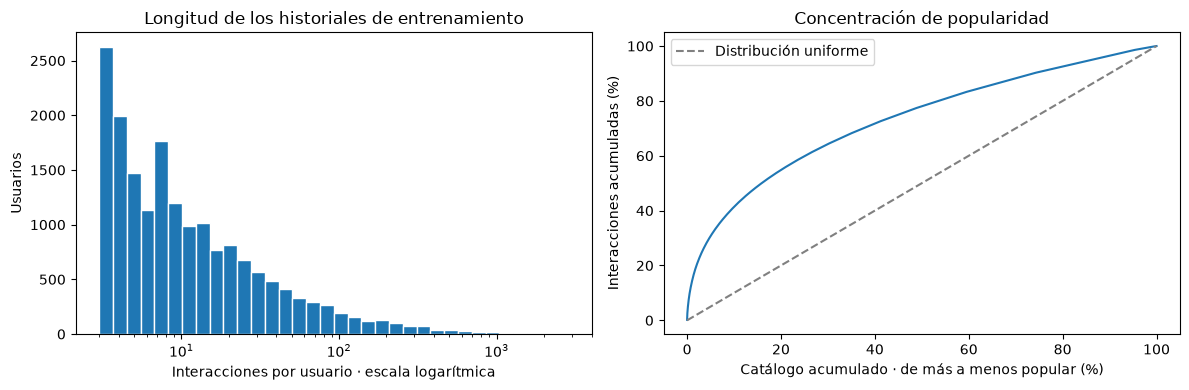

In [9]:
import matplotlib.pyplot as plt

RESULTADOS = PROYECTO / "Resultados"
RESULTADOS.mkdir(parents=True, exist_ok=True)

train_df = datos_ordenados.loc[
    datos_ordenados["particion"] == "train"
].copy()

longitudes_train = train_df.groupby("user_idx").size()

# Incluimos todo el catálogo, incluso la receta sin datos de entrenamiento
popularidad_train = (
    train_df.groupby("item_idx")["user_idx"]
    .nunique()
    .reindex(range(1, N_ITEMS + 1), fill_value=0)
    .sort_values(ascending=False)
)

densidad = len(train_df) / (N_USUARIOS * N_ITEMS)
n_top10 = max(1, int(np.ceil(N_ITEMS * 0.10)))
cuota_top10 = popularidad_train.iloc[:n_top10].sum() / len(train_df)

resumen_eda = pd.Series({
    "Interacciones de entrenamiento": len(train_df),
    "Usuarios": N_USUARIOS,
    "Recetas del catálogo": N_ITEMS,
    "Mediana del historial": longitudes_train.median(),
    "Promedio del historial": longitudes_train.mean(),
    "Percentil 90 del historial": longitudes_train.quantile(0.90),
    "Historial máximo": longitudes_train.max(),
    "Densidad (%)": 100 * densidad,
    "Interacciones en el 10% más popular (%)": 100 * cuota_top10,
})

display(resumen_eda.to_frame("Valor").round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Agrupación logarítmica para mostrar también historiales muy largos
bins = np.geomspace(
    longitudes_train.min(),
    longitudes_train.max() + 1,
    35
)

axes[0].hist(longitudes_train, bins=bins, edgecolor="white")
axes[0].set_xscale("log")
axes[0].set_title("Longitud de los historiales de entrenamiento")
axes[0].set_xlabel("Interacciones por usuario · escala logarítmica")
axes[0].set_ylabel("Usuarios")

porcentaje_catalogo = (
    np.arange(1, N_ITEMS + 1) / N_ITEMS * 100
)
porcentaje_acumulado = (
    popularidad_train.cumsum().to_numpy() / len(train_df) * 100
)

axes[1].plot(porcentaje_catalogo, porcentaje_acumulado)
axes[1].plot([0, 100], [0, 100], "--", color="gray",
             label="Distribución uniforme")
axes[1].set_title("Concentración de popularidad")
axes[1].set_xlabel("Catálogo acumulado · de más a menos popular (%)")
axes[1].set_ylabel("Interacciones acumuladas (%)")
axes[1].legend()

plt.tight_layout()
fig.savefig(
    RESULTADOS / "01_exploracion_train.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

resumen_eda.to_csv(
    RESULTADOS / "resumen_exploracion.csv",
    header=["valor"]
)

## 4.1. Señal temporal en los historiales

Comparamos la similitud de ingredientes entre recetas consecutivas
con la obtenida al desordenar el historial de cada usuario.

Usamos similitud de Jaccard: ingredientes compartidos divididos
por el total de ingredientes distintos de ambas recetas.

Analizamos solo entrenamiento y excluimos las parejas consecutivas
del mismo día, cuyo orden real desconocemos. Cada usuario recibe
el mismo peso. El contraste usa hasta 2.000 usuarios y 10 permutaciones.

Una diferencia positiva sugiere estructura temporal en ingredientes;
no demuestra causalidad ni garantiza una mejora de SASRec.

In [10]:
import ast

# Convertir las listas guardadas como texto a conjuntos de ingredientes
ingredientes_por_item = {
    int(fila.item_idx): frozenset(
        str(ingrediente).strip().lower()
        for ingrediente in ast.literal_eval(fila.ingredients)
    )
    for fila in mapa_items.itertuples(index=False)
}

def jaccard_items(a, b):
    conjunto_a = ingredientes_por_item[int(a)]
    conjunto_b = ingredientes_por_item[int(b)]
    union = conjunto_a | conjunto_b
    return len(conjunto_a & conjunto_b) / len(union) if union else 0.0

# Recuperar el orden explícitamente
historiales_temporales = {}

for usuario, grupo in train_df.sort_values(
    ["user_idx", "posicion"]
).groupby("user_idx"):
    items = grupo["item_idx"].to_numpy()
    fechas = grupo["date"].to_numpy()

    # Solo transiciones entre días distintos
    posiciones_validas = np.flatnonzero(fechas[1:] > fechas[:-1])

    if len(posiciones_validas) > 0:
        historiales_temporales[int(usuario)] = (
            items, posiciones_validas
        )

rng_orden = np.random.default_rng(SEED)
usuarios_elegibles = np.array(sorted(historiales_temporales))

usuarios_muestra = rng_orden.choice(
    usuarios_elegibles,
    size=min(2_000, len(usuarios_elegibles)),
    replace=False
)

N_PERMUTACIONES = 10
comparaciones = []

for usuario in usuarios_muestra:
    items, posiciones = historiales_temporales[int(usuario)]

    similitud_real = np.mean([
        jaccard_items(items[p], items[p + 1])
        for p in posiciones
    ])

    similitudes_azar = []

    for _ in range(N_PERMUTACIONES):
        mezclados = rng_orden.permutation(items)

        # Mismas posiciones evaluadas y mismas recetas por usuario
        similitudes_azar.append(np.mean([
            jaccard_items(mezclados[p], mezclados[p + 1])
            for p in posiciones
        ]))

    comparaciones.append({
        "user_idx": int(usuario),
        "real": similitud_real,
        "desordenado": np.mean(similitudes_azar),
        "transiciones": len(posiciones),
    })

comparacion_orden = pd.DataFrame(comparaciones)
comparacion_orden["diferencia"] = (
    comparacion_orden["real"] - comparacion_orden["desordenado"]
)

# Bootstrap por usuario: incertidumbre de la diferencia media
diferencias = comparacion_orden["diferencia"].to_numpy()
rng_bootstrap = np.random.default_rng(SEED + 1)

medias_bootstrap = np.array([
    rng_bootstrap.choice(
        diferencias, size=len(diferencias), replace=True
    ).mean()
    for _ in range(1_000)
])

limite_inferior, limite_superior = np.quantile(
    medias_bootstrap, [0.025, 0.975]
)

resumen_orden = pd.Series({
    "Usuarios analizados": len(comparacion_orden),
    "Transiciones reales analizadas": comparacion_orden["transiciones"].sum(),
    "Jaccard medio: orden real": comparacion_orden["real"].mean(),
    "Jaccard medio: desordenado": comparacion_orden["desordenado"].mean(),
    "Diferencia media": diferencias.mean(),
    "IC bootstrap 95%: inferior": limite_inferior,
    "IC bootstrap 95%: superior": limite_superior,
})

display(resumen_orden.to_frame("Valor").round(6))

comparacion_orden.to_csv(
    RESULTADOS / "comparacion_orden_usuarios.csv", index=False
)
resumen_orden.to_csv(
    RESULTADOS / "resumen_senal_temporal.csv", header=["valor"]
)

,Valor
Usuarios analizados,2000.000000
Transiciones reales analizadas,39567.000000
Jaccard medio: orden real,0.048461
Jaccard medio: desordenado,0.047621
Diferencia media,0.000840
IC bootstrap 95%: inferior,-0.000253
IC bootstrap 95%: superior,0.002036


### Hallazgo sobre el orden temporal

En 2.000 usuarios y 39.567 transiciones entre días distintos,
la similitud media de ingredientes fue 0,048461 con orden
cronológico y 0,047621 al desordenar los historiales.

La diferencia fue pequeña (+0,000840) y su intervalo bootstrap
del 95 % incluyó cero [−0,000253; 0,002036]. Este análisis no
aporta evidencia concluyente de mayor similitud de ingredientes
entre recetas consecutivas.

Por ello, no asumimos que el orden mejorará la recomendación.
Evaluaremos su aporte predictivo comparando SASRec con las
líneas base y, como diagnóstico adicional, alterando el orden
del historial de entrada en validación.

## 5. Protocolo de evaluación y métricas

Evaluamos rankings sobre el catálogo completo, excluyendo el
relleno y las recetas ya presentes en el historial de entrada.

Para validación, el historial contiene solo entrenamiento.
Para prueba, contiene entrenamiento y la interacción de validación,
sin actualizar los parámetros del modelo.

Con un único objetivo por usuario:
- HitRate@K: 1 si el objetivo aparece entre los primeros K.
- NDCG@K: 1 / log2(posición + 1) si aparece; 0 en otro caso.
- MRR@K: 1 / posición si aparece; 0 en otro caso.
- Cobertura@K: recetas distintas recomendadas / catálogo completo.

Usamos K = 5, 10 y 20. Reportamos explícitamente MRR truncado
a K; el MRR sin truncar requiere la posición en todo el ranking.
Los objetivos sin evidencia de entrenamiento permanecen incluidos.

In [11]:
KS = (5, 10, 20)

def metricas_usuario(recomendaciones, objetivo, k):
    """La posición comienza en 1; objetivo ausente produce ceros."""
    top_k = list(recomendaciones[:k])

    if objetivo not in top_k:
        return {"HR": 0.0, "NDCG": 0.0, "MRR": 0.0}

    posicion = top_k.index(objetivo) + 1

    return {
        "HR": 1.0,
        "NDCG": 1.0 / np.log2(posicion + 1),
        "MRR": 1.0 / posicion,
    }

def evaluar_rankings(rankings, objetivos, n_items, ks=KS):
    """rankings: diccionario usuario -> lista ordenada de ítems."""
    assert set(rankings) == set(objetivos), (
        "Deben evaluarse exactamente los mismos usuarios."
    )

    for lista in rankings.values():
        assert len(lista) == len(set(lista)), "Hay recomendaciones repetidas."
        assert all(1 <= item <= n_items for item in lista)

    filas = []

    for k in ks:
        valores = [
            metricas_usuario(rankings[u], objetivos[u], k)
            for u in objetivos
        ]

        recomendados = {
            item
            for lista in rankings.values()
            for item in lista[:k]
        }

        filas.append({
            "K": k,
            "HR": np.mean([v["HR"] for v in valores]),
            "NDCG": np.mean([v["NDCG"] for v in valores]),
            "MRR": np.mean([v["MRR"] for v in valores]),
            "Cobertura": len(recomendados) / n_items,
            "Usuarios": len(objetivos),
        })

    return pd.DataFrame(filas)

# Verificación manual: el objetivo 30 ocupa la posición 3
ejemplo = [10, 20, 30, 40, 50]

calculado = metricas_usuario(ejemplo, objetivo=30, k=5)

assert calculado["HR"] == 1.0
assert np.isclose(calculado["NDCG"], 1 / np.log2(4))
assert np.isclose(calculado["MRR"], 1 / 3)
assert metricas_usuario(ejemplo, 30, k=2)["HR"] == 0.0

display(pd.DataFrame({
    "Métrica": ["HR@5", "NDCG@5", "MRR@5"],
    "Cálculo manual": [1.0, 0.5, 1 / 3],
    "Función": [
        calculado["HR"],
        calculado["NDCG"],
        calculado["MRR"],
    ],
}))

print("Verificación manual correcta.")

,Métrica,Cálculo manual,Función
0,HR@5,1.000000,1.000000
1,NDCG@5,0.500000,0.500000
2,MRR@5,0.333333,0.333333


Verificación manual correcta.


## 6. Línea base: popularidad

Ordenamos el catálogo según la cantidad de usuarios que
interactuaron con cada receta en entrenamiento.

Los empates se resuelven por item_idx ascendente.
Para cada usuario excluimos las recetas de su historial de entrada.

Este modelo no aprende preferencias individuales ni utiliza
el orden del historial. Sirve como referencia de bajo costo.

In [12]:
from time import perf_counter

inicio = perf_counter()

# Puntajes calculados exclusivamente con entrenamiento
conteos_pop = (
    train_df.groupby("item_idx")["user_idx"]
    .nunique()
    .reindex(range(1, N_ITEMS + 1), fill_value=0)
)

tabla_pop = conteos_pop.rename("usuarios_train").reset_index()

tabla_pop = tabla_pop.sort_values(
    ["usuarios_train", "item_idx"],
    ascending=[False, True]
)

orden_popularidad = tabla_pop["item_idx"].tolist()
tiempo_ajuste_pop = perf_counter() - inicio

def recomendar_popularidad(historial, top_n=20):
    vistos = set(historial)
    recomendaciones = []

    for item in orden_popularidad:
        if item not in vistos:
            recomendaciones.append(item)

        if len(recomendaciones) == top_n:
            break

    return recomendaciones

# Validación: el historial contiene únicamente entrenamiento
inicio = perf_counter()

rankings_pop_val = {
    u: recomendar_popularidad(train_seq[u], top_n=max(KS))
    for u in sorted(val_target)
}

tiempo_inferencia_pop = perf_counter() - inicio

# Comprobar longitud y exclusión de recetas vistas
assert all(len(lista) == max(KS) for lista in rankings_pop_val.values())
assert all(
    set(rankings_pop_val[u]).isdisjoint(train_seq[u])
    for u in rankings_pop_val
)

metricas_pop_val = evaluar_rankings(
    rankings_pop_val, val_target, N_ITEMS
)

metricas_pop_val.insert(0, "Modelo", "Popularidad")
metricas_pop_val.insert(1, "Particion", "val")

display(metricas_pop_val.round(6))

print(f"Ajuste: {tiempo_ajuste_pop:.3f} segundos")
print(
    "Generación del top-20 por usuario: "
    f"{1000 * tiempo_inferencia_pop / len(rankings_pop_val):.3f} ms"
)

metricas_pop_val.to_csv(
    RESULTADOS / "metricas_popularidad_val.csv",
    index=False
)

,Modelo,Particion,K,HR,NDCG,MRR,Cobertura,Usuarios
0,Popularidad,val,5,0.014877,0.008556,0.006504,0.000752,17813
1,Popularidad,val,10,0.024477,0.011617,0.007743,0.001309,17813
2,Popularidad,val,20,0.040308,0.015579,0.008808,0.002061,17813


Ajuste: 0.022 segundos
Generación del top-20 por usuario: 0.001 ms


In [13]:
# Elegimos de forma reproducible un usuario cuyo objetivo aparece
# entre las posiciones 2 y 20, para ilustrar el descuento por posición.
usuario_demo = next(
    u for u in sorted(rankings_pop_val)
    if val_target[u] in rankings_pop_val[u][1:]
)

objetivo_demo = val_target[usuario_demo]
lista_demo = rankings_pop_val[usuario_demo]
posicion_demo = lista_demo.index(objetivo_demo) + 1

catalogo_demo = mapa_items.set_index("item_idx")

print("Usuario interno:", usuario_demo)
print("Longitud del historial de entrenamiento:", len(train_seq[usuario_demo]))
print("Receta objetivo:", catalogo_demo.loc[objetivo_demo, "name"])
print("Posición del objetivo:", posicion_demo)

tabla_demo = pd.DataFrame({
    "Posición": range(1, len(lista_demo) + 1),
    "item_idx": lista_demo,
})

tabla_demo["Receta"] = tabla_demo["item_idx"].map(catalogo_demo["name"])
tabla_demo["Es objetivo"] = tabla_demo["item_idx"].eq(objetivo_demo)
display(tabla_demo)

verificacion_real = []

for k in KS:
    acierto = posicion_demo <= k

    manual = {
        "HR": float(acierto),
        "NDCG": 1 / np.log2(posicion_demo + 1) if acierto else 0.0,
        "MRR": 1 / posicion_demo if acierto else 0.0,
    }

    automatico = metricas_usuario(lista_demo, objetivo_demo, k)

    for metrica in ["HR", "NDCG", "MRR"]:
        assert np.isclose(manual[metrica], automatico[metrica])

        verificacion_real.append({
            "K": k,
            "Métrica": metrica,
            "Manual": manual[metrica],
            "Función": automatico[metrica],
        })

display(pd.DataFrame(verificacion_real).round(6))

pd.DataFrame(verificacion_real).to_csv(
    RESULTADOS / "verificacion_metricas_usuario_real.csv",
    index=False
)

print("Verificación correcta en un usuario real.")

Usuario interno: 162
Longitud del historial de entrenamiento: 18
Receta objetivo: my family s favorite sloppy joes  pizza joes
Posición del objetivo: 15


,Posición,item_idx,Receta,Es objetivo
0,1,4110,to die for crock pot roast,False
1,2,14181,crock pot chicken with black beans cream cheese,False
2,3,5086,whatever floats your boat brownies,False
3,4,6248,creamy cajun chicken pasta,False
4,5,11297,kittencal s italian melt in your mouth meatballs,False
5,6,3267,jo mama s world famous spaghetti,False
6,7,8799,yes virginia there is a great meatloaf,False
7,8,11263,japanese mum s chicken,False
8,9,3839,banana banana bread,False
9,10,4282,oven fried chicken chimichangas,False


,K,Métrica,Manual,Función
0,5,HR,0.000000,0.000000
1,5,NDCG,0.000000,0.000000
2,5,MRR,0.000000,0.000000
3,10,HR,0.000000,0.000000
4,10,NDCG,0.000000,0.000000
5,10,MRR,0.000000,0.000000
6,20,HR,1.000000,1.000000
7,20,NDCG,0.250000,0.250000
8,20,MRR,0.066667,0.066667


Verificación correcta en un usuario real.


## 7. Línea base: ítem–ítem con coseno

Representamos cada receta mediante un vector binario de usuarios
de entrenamiento y lo normalizamos para calcular similitud coseno.

El puntaje de una candidata es la suma ponderada de sus similitudes
con las últimas 20 recetas del historial. Los pesos decaen como
0,9 elevado a la distancia desde la interacción más reciente.

Excluimos recetas vistas. Los empates se resuelven por popularidad
de entrenamiento y luego por item_idx ascendente.

Los valores de 20 interacciones y decaimiento 0,9 se fijan inicialmente;
cualquier ajuste posterior utilizará solo validación.

Calculamos los puntajes por lotes, sin almacenar una matriz completa
de similitudes entre todas las recetas.

In [14]:
from scipy.sparse import csr_matrix, save_npz
from sklearn.preprocessing import normalize

inicio = perf_counter()

# Matriz receta–usuario construida solo con entrenamiento.
# Fila y columna 0 quedan vacías.
matriz_item_usuario = csr_matrix(
    (
        np.ones(len(train_df), dtype=np.float32),
        (
            train_df["item_idx"].to_numpy(),
            train_df["user_idx"].to_numpy()
        )
    ),
    shape=(N_ITEMS + 1, N_USUARIOS + 1)
)

# Normalización L2 por receta: su producto escalar equivale al coseno
items_normalizados = normalize(
    matriz_item_usuario, norm="l2", axis=1
).tocsr()

tiempo_ajuste_i2i = perf_counter() - inicio

def generar_rankings_i2i(
    historiales, top_n=20, ultimos=20, decaimiento=0.9, lote=128
):
    usuarios = sorted(historiales)
    rankings = {}

    # Orden secundario para resolver empates de puntaje
    candidatos_ordenados = np.asarray(orden_popularidad)

    for inicio_lote in range(0, len(usuarios), lote):
        usuarios_lote = usuarios[inicio_lote:inicio_lote + lote]

        filas, columnas, valores = [], [], []

        for fila, usuario in enumerate(usuarios_lote):
            recientes = historiales[usuario][-ultimos:]
            pesos = decaimiento ** np.arange(
                len(recientes) - 1, -1, -1, dtype=np.float32
            )
            pesos /= pesos.sum()

            filas.extend([fila] * len(recientes))
            columnas.extend(recientes)
            valores.extend(pesos)

        pesos_historial = csr_matrix(
            (
                np.asarray(valores, dtype=np.float32),
                (filas, columnas)
            ),
            shape=(len(usuarios_lote), N_ITEMS + 1)
        )

        # Equivale a sumar cosenos ponderados para cada candidata
        perfiles = pesos_historial @ items_normalizados
        puntajes = (perfiles @ items_normalizados.T).toarray()

        for fila, usuario in enumerate(usuarios_lote):
            puntajes[fila, 0] = -np.inf
            puntajes[fila, historiales[usuario]] = -np.inf

            # Orden estable: conserva popularidad e índice en empates
            orden = np.argsort(
                -puntajes[fila, candidatos_ordenados],
                kind="stable"
            )[:top_n]

            rankings[usuario] = candidatos_ordenados[orden].tolist()

        if inicio_lote % (lote * 20) == 0:
            print(
                f"Usuarios procesados: "
                f"{min(inicio_lote + lote, len(usuarios)):,}"
                f" / {len(usuarios):,}",
                flush=True
            )

    return rankings

inicio = perf_counter()

rankings_i2i_val = generar_rankings_i2i(train_seq)

tiempo_inferencia_i2i = perf_counter() - inicio

assert all(
    len(lista) == max(KS) for lista in rankings_i2i_val.values()
)
assert all(
    set(rankings_i2i_val[u]).isdisjoint(train_seq[u])
    for u in rankings_i2i_val
)

metricas_i2i_val = evaluar_rankings(
    rankings_i2i_val, val_target, N_ITEMS
)
metricas_i2i_val.insert(0, "Modelo", "Item-Item")
metricas_i2i_val.insert(1, "Particion", "val")

display(
    pd.concat(
        [metricas_pop_val, metricas_i2i_val],
        ignore_index=True
    ).round(6)
)

print(f"Ajuste ítem–ítem: {tiempo_ajuste_i2i:.3f} segundos")
print(
    "Generación del top-20 por usuario: "
    f"{1000 * tiempo_inferencia_i2i / len(rankings_i2i_val):.3f} ms"
)

metricas_i2i_val.to_csv(
    RESULTADOS / "metricas_item_item_val.csv", index=False
)

CARPETA_MODELOS = PROYECTO / "modelos"
CARPETA_MODELOS.mkdir(parents=True, exist_ok=True)

save_npz(
    CARPETA_MODELOS / "items_normalizados.npz",
    items_normalizados
)

Usuarios procesados: 128 / 17,813
Usuarios procesados: 2,688 / 17,813
Usuarios procesados: 5,248 / 17,813
Usuarios procesados: 7,808 / 17,813
Usuarios procesados: 10,368 / 17,813
Usuarios procesados: 12,928 / 17,813
Usuarios procesados: 15,488 / 17,813


,Modelo,Particion,K,HR,NDCG,MRR,Cobertura,Usuarios
0,Popularidad,val,5,0.014877,0.008556,0.006504,0.000752,17813
1,Popularidad,val,10,0.024477,0.011617,0.007743,0.001309,17813
2,Popularidad,val,20,0.040308,0.015579,0.008808,0.002061,17813
3,Item-Item,val,5,0.006681,0.004638,0.003970,0.473448,17813
4,Item-Item,val,10,0.010779,0.005970,0.004524,0.624830,17813
5,Item-Item,val,20,0.016673,0.007464,0.004936,0.766974,17813


Ajuste ítem–ítem: 0.004 segundos
Generación del top-20 por usuario: 1.675 ms


## 8. Línea base: reglas de asociación

Cada historial de entrenamiento se considera una canasta sin orden.

Extraemos conjuntos frecuentes de hasta dos recetas con FP-Growth,
usando soporte mínimo de 0,005. Construimos reglas A → B y
calculamos confianza y lift únicamente con entrenamiento.

Para recomendar, activamos las reglas cuyo antecedente está en el
historial y cuyo consecuente no ha sido visto. Si varias reglas
proponen la misma receta, conservamos la de mayor lift.

Ordenamos por lift, confianza, soporte e índice de receta.
Si faltan recomendaciones, completamos con popularidad.

In [16]:
from mlxtend.frequent_patterns import fpgrowth

MIN_SUPPORT = 0.005
inicio = perf_counter()

# Descartar recetas que no pueden alcanzar el soporte mínimo.
# Esto no elimina usuarios ni cambia el denominador del soporte.
soportes_items = conteos_pop / N_USUARIOS
items_frecuentes = soportes_items[
    soportes_items >= MIN_SUPPORT
].index.to_numpy()

# Una fila por usuario, incluyendo los que no tienen ítems frecuentes
canastas_sparse = (
    matriz_item_usuario[items_frecuentes, 1:].T
).astype(bool)

canastas = pd.DataFrame.sparse.from_spmatrix(
    canastas_sparse,
    columns=items_frecuentes
)

canastas.columns = canastas.columns.astype(str)

frecuentes = fpgrowth(
    canastas,
    min_support=MIN_SUPPORT,
    use_colnames=True,
    max_len=2
)

frecuentes["itemsets"] = frecuentes["itemsets"].apply(
    lambda conjunto: frozenset(int(item) for item in conjunto)
)

# Reglas de un antecedente y un consecuente
soportes_individuales = {
    next(iter(fila.itemsets)): fila.support
    for fila in frecuentes.itertuples(index=False)
    if len(fila.itemsets) == 1
}

filas_reglas = []

for fila in frecuentes.itertuples(index=False):
    if len(fila.itemsets) != 2:
        continue

    a, b = sorted(fila.itemsets)

    for antecedente, consecuente in [(a, b), (b, a)]:
        confianza = fila.support / soportes_individuales[antecedente]
        lift = confianza / soportes_individuales[consecuente]

        if lift > 1:
            filas_reglas.append({
                "antecedente": int(antecedente),
                "consecuente": int(consecuente),
                "support": fila.support,
                "confidence": confianza,
                "lift": lift,
            })

reglas = pd.DataFrame(
    filas_reglas,
    columns=[
        "antecedente", "consecuente", "support", "confidence", "lift"
    ]
).sort_values(
    ["lift", "confidence", "support", "consecuente", "antecedente"],
    ascending=[False, False, False, True, True]
).reset_index(drop=True)

# Índice de reglas para evitar revisar todas por cada usuario
reglas_por_antecedente = {}

for regla in reglas.itertuples(index=False):
    reglas_por_antecedente.setdefault(regla.antecedente, []).append(
        (
            regla.consecuente,
            regla.lift,
            regla.confidence,
            regla.support
        )
    )

tiempo_ajuste_reglas = perf_counter() - inicio

def recomendar_reglas(historial, top_n=20):
    vistos = set(historial)
    candidatos = {}

    for antecedente in vistos:
        for item, lift, confianza, soporte in (
            reglas_por_antecedente.get(antecedente, [])
        ):
            if item in vistos:
                continue

            calidad = (lift, confianza, soporte)

            if item not in candidatos or calidad > candidatos[item]:
                candidatos[item] = calidad

    ordenados = sorted(
        candidatos,
        key=lambda item: (
            -candidatos[item][0],
            -candidatos[item][1],
            -candidatos[item][2],
            item
        )
    )

    recomendaciones = ordenados[:top_n]
    seleccionados = set(recomendaciones)

    # Respaldo explícito por popularidad
    if len(recomendaciones) < top_n:
        for item in orden_popularidad:
            if item not in vistos and item not in seleccionados:
                recomendaciones.append(item)
                seleccionados.add(item)

            if len(recomendaciones) == top_n:
                break

    return recomendaciones, min(len(ordenados), top_n)

inicio = perf_counter()

rankings_reglas_val = {}
cantidad_por_reglas = []

for usuario in sorted(val_target):
    lista, cantidad = recomendar_reglas(train_seq[usuario])
    rankings_reglas_val[usuario] = lista
    cantidad_por_reglas.append(cantidad)

tiempo_inferencia_reglas = perf_counter() - inicio

assert all(
    set(rankings_reglas_val[u]).isdisjoint(train_seq[u])
    for u in rankings_reglas_val
)
assert all(len(lista) == 20 for lista in rankings_reglas_val.values())

metricas_reglas_val = evaluar_rankings(
    rankings_reglas_val, val_target, N_ITEMS
)
metricas_reglas_val.insert(0, "Modelo", "Reglas + popularidad")
metricas_reglas_val.insert(1, "Particion", "val")

print(f"Recetas frecuentes: {len(items_frecuentes):,}")
print(f"Reglas con lift > 1: {len(reglas):,}")
print(
    "Usuarios con al menos una recomendación por reglas: "
    f"{100 * np.mean(np.array(cantidad_por_reglas) > 0):.2f}%"
)
print(
    "Promedio de recomendaciones por reglas dentro del top-20: "
    f"{np.mean(cantidad_por_reglas):.2f}"
)
print(f"Ajuste: {tiempo_ajuste_reglas:.3f} segundos")
print(
    "Generación del top-20 por usuario: "
    f"{1000 * tiempo_inferencia_reglas / N_USUARIOS:.3f} ms"
)

display(reglas.head(10))

display(pd.concat(
    [metricas_pop_val, metricas_i2i_val, metricas_reglas_val],
    ignore_index=True
).round(6))

reglas.to_csv(
    CARPETA_MODELOS / "reglas_asociacion.csv", index=False
)
metricas_reglas_val.to_csv(
    RESULTADOS / "metricas_reglas_val.csv", index=False
)

Recetas frecuentes: 464
Reglas con lift > 1: 54
Usuarios con al menos una recomendación por reglas: 28.46%
Promedio de recomendaciones por reglas dentro del top-20: 1.56
Ajuste: 0.181 segundos
Generación del top-20 por usuario: 0.003 ms


,antecedente,consecuente,support,confidence,lift
0,13061,11297,0.006231,0.191050,5.179866
1,11297,13061,0.006231,0.168950,5.179866
2,15089,4110,0.006288,0.244009,4.556108
3,4110,15089,0.006288,0.117400,4.556108
4,15089,14181,0.005277,0.204793,4.136030
5,14181,15089,0.005277,0.106576,4.136030
6,5320,4110,0.005165,0.220624,4.119462
7,4110,5320,0.005165,0.096436,4.119462
8,3267,6248,0.006063,0.164885,4.051180
9,6248,3267,0.006063,0.148966,4.051180


,Modelo,Particion,K,HR,NDCG,MRR,Cobertura,Usuarios
0,Popularidad,val,5,0.014877,0.008556,0.006504,0.000752,17813
1,Popularidad,val,10,0.024477,0.011617,0.007743,0.001309,17813
2,Popularidad,val,20,0.040308,0.015579,0.008808,0.002061,17813
3,Item-Item,val,5,0.006681,0.004638,0.003970,0.473448,17813
4,Item-Item,val,10,0.010779,0.005970,0.004524,0.624830,17813
5,Item-Item,val,20,0.016673,0.007464,0.004936,0.766974,17813
6,Reglas + popularidad,val,5,0.014540,0.008507,0.006539,0.000727,17813
7,Reglas + popularidad,val,10,0.024252,0.011619,0.007807,0.001309,17813
8,Reglas + popularidad,val,20,0.040308,0.015637,0.008889,0.002061,17813


## 9. Transformer secuencial: SASRec

Cada receta se representa mediante un embedding aprendido, al que
sumamos un embedding de posición.

Los bloques contienen:
1. Normalización y autoatención causal.
2. Conexión residual.
3. Normalización y red feed-forward.
4. Otra conexión residual.

La máscara causal impide que una posición observe recetas futuras.
Otra máscara excluye los ceros de relleno.

Usamos relleno a la derecha. Durante entrenamiento, la representación
de cada posición servirá para predecir la siguiente receta.
Los puntajes se obtienen mediante productos escalares con los
embeddings de las recetas.

In [17]:
import math
from torch import nn

DEVICE = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

class BloqueSASRec(nn.Module):
    def __init__(self, dimension, cabezas, dropout):
        super().__init__()

        self.norm_atencion = nn.LayerNorm(dimension)

        self.atencion = nn.MultiheadAttention(
            embed_dim=dimension,
            num_heads=cabezas,
            dropout=dropout,
            batch_first=True
        )

        self.norm_ff = nn.LayerNorm(dimension)

        self.feed_forward = nn.Sequential(
            nn.Linear(dimension, 4 * dimension),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(4 * dimension, dimension)
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mascara_causal, mascara_padding,
                devolver_atencion=False):
        normalizado = self.norm_atencion(x)

        salida, pesos = self.atencion(
            normalizado,
            normalizado,
            normalizado,
            attn_mask=mascara_causal,
            key_padding_mask=mascara_padding,
            need_weights=devolver_atencion,
            average_attn_weights=False
        )

        x = x + self.dropout(salida)
        x = x + self.dropout(self.feed_forward(self.norm_ff(x)))

        # Mantener en cero las posiciones de relleno
        x = x.masked_fill(mascara_padding.unsqueeze(-1), 0.0)

        return x, pesos


class SASRec(nn.Module):
    def __init__(
        self, n_items, max_len=50, dimension=64,
        cabezas=2, bloques=1, dropout=0.2
    ):
        super().__init__()

        self.max_len = max_len
        self.dimension = dimension

        self.item_embedding = nn.Embedding(
            n_items + 1, dimension, padding_idx=0
        )
        self.pos_embedding = nn.Embedding(max_len, dimension)
        self.dropout = nn.Dropout(dropout)

        self.bloques = nn.ModuleList([
            BloqueSASRec(dimension, cabezas, dropout)
            for _ in range(bloques)
        ])

        self.norm_final = nn.LayerNorm(dimension)

        nn.init.normal_(self.item_embedding.weight, std=0.02)
        nn.init.normal_(self.pos_embedding.weight, std=0.02)

        with torch.no_grad():
            self.item_embedding.weight[0].zero_()

    def forward(self, items, devolver_atencion=False):
        # items: [usuarios del lote, posiciones]
        longitud = items.size(1)
        posiciones = torch.arange(longitud, device=items.device)

        mascara_padding = items.eq(0)

        x = (
            self.item_embedding(items) * math.sqrt(self.dimension)
            + self.pos_embedding(posiciones).unsqueeze(0)
        )

        x = self.dropout(x)
        x = x.masked_fill(mascara_padding.unsqueeze(-1), 0.0)

        # True sobre la diagonal: bloquear posiciones futuras
        mascara_causal = torch.triu(
            torch.ones(
                longitud, longitud,
                dtype=torch.bool, device=items.device
            ),
            diagonal=1
        )

        atenciones = []

        for bloque in self.bloques:
            x, pesos = bloque(
                x, mascara_causal, mascara_padding,
                devolver_atencion
            )

            if devolver_atencion:
                atenciones.append(pesos)

        x = self.norm_final(x)
        x = x.masked_fill(mascara_padding.unsqueeze(-1), 0.0)

        if devolver_atencion:
            return x, atenciones

        return x


# Comprobación pequeña en CPU, sin entrenamiento
torch.manual_seed(SEED)

modelo_prueba = SASRec(
    N_ITEMS, max_len=5, dimension=32,
    cabezas=2, bloques=1, dropout=0.0
).eval()

entrada_a = torch.tensor([[1, 2, 3, 0, 0]])
entrada_b = torch.tensor([[1, 2, 4, 0, 0]])

with torch.no_grad():
    salida_a, atenciones = modelo_prueba(
        entrada_a, devolver_atencion=True
    )
    salida_b = modelo_prueba(entrada_b)

# Cambiar la tercera receta no puede afectar las dos primeras
assert torch.allclose(
    salida_a[:, :2], salida_b[:, :2], atol=1e-6
)

assert torch.isfinite(salida_a).all()
assert torch.count_nonzero(salida_a[:, 3:]) == 0

# Las dos primeras posiciones no pueden atender a la tercera
assert atenciones[0][0, :, :2, 2].abs().max().item() < 1e-6

print("Máscara causal: correcta")
print("Relleno: correcto")
print("Dimensiones de salida:", tuple(salida_a.shape))
print("Dispositivo previsto para entrenar:", DEVICE)

del modelo_prueba

Máscara causal: correcta
Relleno: correcto
Dimensiones de salida: (1, 5, 32)
Dispositivo previsto para entrenar: mps


## 9.1. Ejemplos de entrenamiento y configuraciones

Construimos entradas y objetivos desplazados una posición:
entrada [A, B, C] → objetivos [B, C, D].

Dividimos los historiales de entrenamiento en bloques de hasta
50 posiciones. Conservamos todos los pares consecutivos y
completamos con ceros a la derecha.

Entrenaremos con pérdida binaria sobre una receta positiva y
una negativa muestreada por posición válida. Las negativas
provienen de recetas observadas en entrenamiento y excluyen
el historial de entrenamiento del usuario.

El muestreo no consulta validación ni prueba. Una negativa
representa una interacción no observada, no un rechazo explícito.

Compararemos tres configuraciones con validación, usando
NDCG@10 como criterio de selección y parada temprana.

In [18]:
from torch.utils.data import Dataset, DataLoader

MAX_LEN = 50
BATCH_SIZE = 128

# Solo recetas con evidencia de entrenamiento
pool_negativos = np.array(sorted(items_train), dtype=np.int64)


class DatasetSecuencial(Dataset):
    def __init__(self, historiales, max_len=50, seed=42):
        self.max_len = max_len
        self.rng = np.random.default_rng(seed)

        self.vistos = {
            u: set(historial)
            for u, historial in historiales.items()
        }

        self.ejemplos = []

        for usuario in sorted(historiales):
            historial = historiales[usuario]

            # Cada bloque contiene hasta max_len pares entrada-objetivo
            for inicio in range(0, len(historial) - 1, max_len):
                fragmento = historial[inicio:inicio + max_len + 1]

                entrada = np.zeros(max_len, dtype=np.int64)
                positivo = np.zeros(max_len, dtype=np.int64)

                cantidad = len(fragmento) - 1
                entrada[:cantidad] = fragmento[:-1]
                positivo[:cantidad] = fragmento[1:]

                self.ejemplos.append(
                    (usuario, entrada, positivo, cantidad)
                )

    def __len__(self):
        return len(self.ejemplos)

    def __getitem__(self, indice):
        usuario, entrada, positivo, cantidad = self.ejemplos[indice]
        negativo = np.zeros(self.max_len, dtype=np.int64)

        # Rechazo de candidatos ya observados en entrenamiento
        candidatos = self.rng.choice(pool_negativos, size=cantidad)

        invalidos = np.array([
            item in self.vistos[usuario] for item in candidatos
        ])

        while invalidos.any():
            candidatos[invalidos] = self.rng.choice(
                pool_negativos, size=int(invalidos.sum())
            )
            invalidos = np.array([
                item in self.vistos[usuario] for item in candidatos
            ])

        negativo[:cantidad] = candidatos

        return (
            torch.from_numpy(entrada),
            torch.from_numpy(positivo),
            torch.from_numpy(negativo)
        )


def crear_loader_entrenamiento(seed=SEED):
    dataset = DatasetSecuencial(
        train_seq, max_len=MAX_LEN, seed=seed
    )

    generador = torch.Generator().manual_seed(seed)

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generador,
        num_workers=0,
        drop_last=False
    )

    return dataset, loader


# Loader de comprobación; recrearemos uno nuevo para cada configuración
dataset_train, loader_train = crear_loader_entrenamiento()

pares_esperados = sum(len(s) - 1 for s in train_seq.values())
pares_generados = sum(
    ejemplo[3] for ejemplo in dataset_train.ejemplos
)

assert pares_generados == pares_esperados

entrada, positivo, negativo = next(iter(loader_train))
validos = positivo.ne(0)

assert entrada.shape == positivo.shape == negativo.shape
assert torch.all(negativo[validos] > 0)
assert torch.all(negativo[~validos] == 0)
assert torch.all(positivo[validos] != negativo[validos])

CONFIGURACIONES = [
    {
        "nombre": "SASRec_A",
        "dimension": 64,
        "cabezas": 2,
        "bloques": 1,
        "dropout": 0.2,
        "lr": 0.001,
    },
    {
        "nombre": "SASRec_B",
        "dimension": 64,
        "cabezas": 2,
        "bloques": 2,
        "dropout": 0.2,
        "lr": 0.001,
    },
    {
        "nombre": "SASRec_C",
        "dimension": 128,
        "cabezas": 2,
        "bloques": 1,
        "dropout": 0.3,
        "lr": 0.0005,
    },
]

print(f"Bloques de entrenamiento: {len(dataset_train):,}")
print(f"Pares entrada–objetivo: {pares_generados:,}")
print(f"Lotes por época: {len(loader_train):,}")
print("Forma del lote:", tuple(entrada.shape))
print("Preparación correcta.")

display(pd.DataFrame(CONFIGURACIONES))

Bloques de entrenamiento: 23,722
Pares entrada–objetivo: 502,179
Lotes por época: 186
Forma del lote: (128, 50)
Preparación correcta.


,nombre,dimension,cabezas,bloques,dropout,lr
0,SASRec_A,64,2,1,0.2,0.0010
1,SASRec_B,64,2,2,0.2,0.0010
2,SASRec_C,128,2,1,0.3,0.0005


## 9.2. Entrenamiento y selección con validación

Minimizamos la suma de dos pérdidas BCEWithLogits:
una para el siguiente ítem observado y otra para un negativo muestreado.
La pérdida se promedia únicamente sobre posiciones sin relleno.

Usamos Adam, recorte de gradiente y semilla fija por configuración.
Evaluamos validación contra el catálogo completo, excluyendo
el relleno y todas las recetas del historial de entrenamiento.

La selección utiliza NDCG@10, con un máximo de 20 épocas
y paciencia de 3 épocas sin mejora. Guardamos la mejor época
de cada configuración. No consultamos prueba durante esta selección.

En inferencia usamos las últimas 50 recetas del historial.
Los empates de puntaje de SASRec se resuelven por item_idx ascendente.

In [19]:
import copy
import json
import torch.nn.functional as F


def sincronizar_dispositivo():
    if DEVICE.type == "mps":
        torch.mps.synchronize()


@torch.no_grad()
def generar_rankings_sasrec(
    modelo, historiales, top_n=20, lote=128
):
    modelo.eval()
    usuarios = sorted(historiales)
    rankings = {}

    for inicio in range(0, len(usuarios), lote):
        usuarios_lote = usuarios[inicio:inicio + lote]

        entradas = np.zeros(
            (len(usuarios_lote), modelo.max_len),
            dtype=np.int64
        )
        longitudes = []

        for fila, usuario in enumerate(usuarios_lote):
            recientes = historiales[usuario][-modelo.max_len:]
            entradas[fila, :len(recientes)] = recientes
            longitudes.append(len(recientes))

        assert min(longitudes) > 0

        entradas = torch.from_numpy(entradas).to(DEVICE)
        representaciones = modelo(entradas)

        posiciones_finales = torch.tensor(
            longitudes, device=DEVICE
        ) - 1

        perfiles = representaciones[
            torch.arange(len(usuarios_lote), device=DEVICE),
            posiciones_finales
        ]

        puntajes = (
            perfiles @ modelo.item_embedding.weight.T
        ).cpu().numpy()

        if not np.isfinite(puntajes).all():
            raise ValueError("Puntajes no finitos durante evaluación.")

        puntajes[:, 0] = -np.inf

        for fila, usuario in enumerate(usuarios_lote):
            # Excluir TODO el historial, no solo las últimas 50 recetas
            puntajes[fila, historiales[usuario]] = -np.inf

            orden = np.argsort(
                -puntajes[fila], kind="stable"
            )[:top_n]

            rankings[usuario] = orden.tolist()

    return rankings


def entrenar_configuracion(config, max_epocas=20, paciencia=3):
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    # Reiniciar también el muestreo y el orden de los lotes
    dataset, loader = crear_loader_entrenamiento(seed=SEED)

    arquitectura = {
        clave: config[clave]
        for clave in ["dimension", "cabezas", "bloques", "dropout"]
    }

    modelo = SASRec(
        n_items=N_ITEMS,
        max_len=MAX_LEN,
        **arquitectura
    ).to(DEVICE)

    optimizador = torch.optim.Adam(
        modelo.parameters(), lr=config["lr"]
    )

    mejor_ndcg = -np.inf
    mejor_estado = None
    mejor_epoca = 0
    sin_mejora = 0
    registros = []

    sincronizar_dispositivo()
    inicio_total = perf_counter()

    for epoca in range(1, max_epocas + 1):
        modelo.train()
        perdida_acumulada = 0.0
        posiciones_acumuladas = 0

        sincronizar_dispositivo()
        inicio_epoca = perf_counter()

        for entradas, positivos, negativos in loader:
            entradas = entradas.to(DEVICE)
            positivos = positivos.to(DEVICE)
            negativos = negativos.to(DEVICE)

            optimizador.zero_grad(set_to_none=True)

            representaciones = modelo(entradas)
            validos = positivos.ne(0)

            # Solo posiciones reales
            h = representaciones[validos]
            emb_positivos = modelo.item_embedding(positivos[validos])
            emb_negativos = modelo.item_embedding(negativos[validos])

            logits_positivos = (h * emb_positivos).sum(dim=-1)
            logits_negativos = (h * emb_negativos).sum(dim=-1)

            perdida = (
                F.binary_cross_entropy_with_logits(
                    logits_positivos,
                    torch.ones_like(logits_positivos)
                )
                + F.binary_cross_entropy_with_logits(
                    logits_negativos,
                    torch.zeros_like(logits_negativos)
                )
            )

            if not torch.isfinite(perdida).item():
                raise ValueError("Pérdida no finita.")

            perdida.backward()
            nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
            optimizador.step()

            cantidad = h.size(0)
            perdida_acumulada += perdida.item() * cantidad
            posiciones_acumuladas += cantidad

        sincronizar_dispositivo()
        segundos_train = perf_counter() - inicio_epoca

        inicio_val = perf_counter()

        rankings_val = generar_rankings_sasrec(
            modelo, train_seq, top_n=20
        )

        metricas_val = evaluar_rankings(
            rankings_val, val_target, N_ITEMS
        )

        sincronizar_dispositivo()
        segundos_val = perf_counter() - inicio_val

        fila10 = metricas_val.loc[metricas_val["K"] == 10].iloc[0]
        ndcg10 = float(fila10["NDCG"])
        perdida_media = perdida_acumulada / posiciones_acumuladas

        registros.append({
            "Modelo": config["nombre"],
            "Epoca": epoca,
            "Perdida_train": perdida_media,
            "NDCG10_val": ndcg10,
            "HR10_val": float(fila10["HR"]),
            "Segundos_train": segundos_train,
            "Segundos_val": segundos_val,
        })

        if ndcg10 > mejor_ndcg:
            mejor_ndcg = ndcg10
            mejor_epoca = epoca

            # Copia independiente en CPU para guardar el checkpoint
            mejor_estado = {
                nombre: tensor.detach().cpu().clone()
                for nombre, tensor in modelo.state_dict().items()
            }
            sin_mejora = 0
        else:
            sin_mejora += 1

        print(
            f"{config['nombre']} | época {epoca:02d} | "
            f"loss {perdida_media:.4f} | "
            f"NDCG@10 {ndcg10:.6f} | "
            f"train {segundos_train:.1f}s | val {segundos_val:.1f}s",
            flush=True
        )

        # Guardar las curvas después de cada época
        pd.DataFrame(registros).to_csv(
            RESULTADOS / f"curva_{config['nombre']}.csv",
            index=False
        )

        if sin_mejora >= paciencia:
            print(
                f"Parada temprana. Mejor época: {mejor_epoca}",
                flush=True
            )
            break

    sincronizar_dispositivo()
    segundos_total = perf_counter() - inicio_total

    checkpoint = {
        "config": dict(config),
        "n_items": N_ITEMS,
        "max_len": MAX_LEN,
        "seed": SEED,
        "mejor_epoca": mejor_epoca,
        "ndcg10_val": mejor_ndcg,
        "state_dict": mejor_estado,
    }

    torch.save(
        checkpoint,
        CARPETA_MODELOS / f"{config['nombre']}.pt"
    )

    resumen = {
        "Modelo": config["nombre"],
        "Mejor_epoca": mejor_epoca,
        "NDCG10_val": mejor_ndcg,
        "Parametros": sum(p.numel() for p in modelo.parameters()),
        "Segundos_total": segundos_total,
    }

    del modelo, optimizador

    if DEVICE.type == "mps":
        torch.mps.empty_cache()

    return resumen, registros


Entrenando SASRec_A...
SASRec_A | época 01 | loss 1.2937 | NDCG@10 0.011258 | train 4.0s | val 39.1s
SASRec_A | época 02 | loss 1.1587 | NDCG@10 0.010876 | train 1.8s | val 39.2s
SASRec_A | época 03 | loss 1.0843 | NDCG@10 0.011831 | train 1.8s | val 39.2s
SASRec_A | época 04 | loss 1.0187 | NDCG@10 0.010418 | train 1.9s | val 39.0s
SASRec_A | época 05 | loss 0.9516 | NDCG@10 0.009844 | train 1.8s | val 39.0s
SASRec_A | época 06 | loss 0.8844 | NDCG@10 0.008000 | train 1.8s | val 39.0s
Parada temprana. Mejor época: 3

Entrenando SASRec_B...
SASRec_B | época 01 | loss 1.2847 | NDCG@10 0.010960 | train 2.4s | val 40.1s
SASRec_B | época 02 | loss 1.1645 | NDCG@10 0.011002 | train 2.4s | val 39.6s
SASRec_B | época 03 | loss 1.0967 | NDCG@10 0.011104 | train 3.7s | val 39.4s
SASRec_B | época 04 | loss 1.0370 | NDCG@10 0.010533 | train 3.0s | val 39.4s
SASRec_B | época 05 | loss 0.9748 | NDCG@10 0.010145 | train 3.6s | val 39.6s
SASRec_B | época 06 | loss 0.9099 | NDCG@10 0.008764 | train 3

,Modelo,Mejor_epoca,NDCG10_val,Parametros,Segundos_total
0,SASRec_A,3,0.011831,2692736,247.680589
2,SASRec_C,3,0.011775,5483776,258.807517
1,SASRec_B,3,0.011104,2742720,256.933585


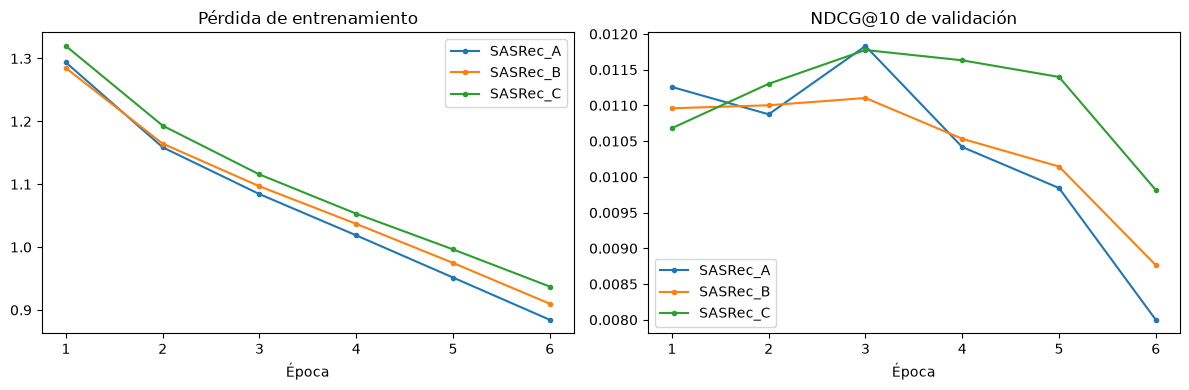

Modelo seleccionado: SASRec_A
Mejor época: 3
Modelo guardado: sasrec.pt (10.78 MB)


In [20]:
resumenes_sasrec = []
curvas_sasrec = []

for config in CONFIGURACIONES:
    print(f"\nEntrenando {config['nombre']}...", flush=True)

    resumen, registros = entrenar_configuracion(config)

    resumenes_sasrec.append(resumen)
    curvas_sasrec.extend(registros)

    pd.DataFrame(resumenes_sasrec).to_csv(
        RESULTADOS / "seleccion_sasrec_val.csv",
        index=False
    )

seleccion_sasrec = pd.DataFrame(resumenes_sasrec).sort_values(
    ["NDCG10_val", "Parametros"],
    ascending=[False, True]
)

display(seleccion_sasrec)

# Recuperar la mejor configuración seleccionada SOLO con validación
nombre_ganador = seleccion_sasrec.iloc[0]["Modelo"]

checkpoint_ganador = torch.load(
    CARPETA_MODELOS / f"{nombre_ganador}.pt",
    map_location="cpu",
    weights_only=True
)

torch.save(
    checkpoint_ganador,
    CARPETA_MODELOS / "sasrec.pt"
)

config_ganadora = checkpoint_ganador["config"]

modelo_sasrec = SASRec(
    N_ITEMS,
    max_len=checkpoint_ganador["max_len"],
    **{
        clave: config_ganadora[clave]
        for clave in ["dimension", "cabezas", "bloques", "dropout"]
    }
).to(DEVICE)

modelo_sasrec.load_state_dict(checkpoint_ganador["state_dict"])
modelo_sasrec.eval()

# Curvas de pérdida y NDCG por época
curvas_df = pd.DataFrame(curvas_sasrec)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for nombre, grupo in curvas_df.groupby("Modelo"):
    axes[0].plot(
        grupo["Epoca"], grupo["Perdida_train"],
        marker=".", label=nombre
    )
    axes[1].plot(
        grupo["Epoca"], grupo["NDCG10_val"],
        marker=".", label=nombre
    )

axes[0].set_title("Pérdida de entrenamiento")
axes[1].set_title("NDCG@10 de validación")

for ax in axes:
    ax.set_xlabel("Época")
    ax.legend()

plt.tight_layout()
fig.savefig(
    RESULTADOS / "curvas_sasrec.png",
    dpi=160, bbox_inches="tight"
)
plt.show()

peso_mb = (CARPETA_MODELOS / "sasrec.pt").stat().st_size / 1_000_000
assert peso_mb < 100, "El modelo excede el límite del certamen."

print("Modelo seleccionado:", nombre_ganador)
print("Mejor época:", checkpoint_ganador["mejor_epoca"])
print(f"Modelo guardado: sasrec.pt ({peso_mb:.2f} MB)")

In [21]:
# Evaluación del mejor checkpoint en validación.
# No se entrena ni se consulta prueba.
inicio = perf_counter()

rankings_sasrec_val = generar_rankings_sasrec(
    modelo_sasrec, train_seq, top_n=max(KS)
)

sincronizar_dispositivo()
tiempo_inferencia_sasrec = perf_counter() - inicio

assert all(
    len(lista) == max(KS)
    for lista in rankings_sasrec_val.values()
)
assert all(
    set(rankings_sasrec_val[u]).isdisjoint(train_seq[u])
    for u in rankings_sasrec_val
)

metricas_sasrec_val = evaluar_rankings(
    rankings_sasrec_val, val_target, N_ITEMS
)
metricas_sasrec_val.insert(0, "Modelo", "SASRec")
metricas_sasrec_val.insert(1, "Particion", "val")

# Comprobar que recuperamos el checkpoint seleccionado
ndcg_recuperado = metricas_sasrec_val.loc[
    metricas_sasrec_val["K"] == 10, "NDCG"
].iloc[0]

assert np.isclose(
    ndcg_recuperado,
    checkpoint_ganador["ndcg10_val"],
    atol=1e-6
), "La evaluación no coincide con el checkpoint seleccionado."

comparacion_val = pd.concat(
    [
        metricas_pop_val,
        metricas_i2i_val,
        metricas_reglas_val,
        metricas_sasrec_val
    ],
    ignore_index=True
)

display(comparacion_val.round(6))

comparacion_val.to_csv(
    RESULTADOS / "comparacion_modelos_val.csv",
    index=False
)

print(
    "Generación del top-20 por usuario, en lotes: "
    f"{1000 * tiempo_inferencia_sasrec / N_USUARIOS:.3f} ms"
)
print("Checkpoint seleccionado verificado.")

,Modelo,Particion,K,HR,NDCG,MRR,Cobertura,Usuarios
0,Popularidad,val,5,0.014877,0.008556,0.006504,0.000752,17813
1,Popularidad,val,10,0.024477,0.011617,0.007743,0.001309,17813
2,Popularidad,val,20,0.040308,0.015579,0.008808,0.002061,17813
3,Item-Item,val,5,0.006681,0.004638,0.003970,0.473448,17813
4,Item-Item,val,10,0.010779,0.005970,0.004524,0.624830,17813
5,Item-Item,val,20,0.016673,0.007464,0.004936,0.766974,17813
6,Reglas + popularidad,val,5,0.014540,0.008507,0.006539,0.000727,17813
7,Reglas + popularidad,val,10,0.024252,0.011619,0.007807,0.001309,17813
8,Reglas + popularidad,val,20,0.040308,0.015637,0.008889,0.002061,17813
9,SASRec,val,5,0.013361,0.008539,0.006960,0.008244,17813


Generación del top-20 por usuario, en lotes: 2.161 ms
Checkpoint seleccionado verificado.


## 9.3. Sensibilidad al orden en validación

Conservamos el modelo entrenado y los objetivos de validación.
Desordenamos las últimas 50 recetas de cada historial, manteniendo
los mismos ítems visibles y las mismas exclusiones de recetas vistas.

Comparamos NDCG@10 por usuario con el orden cronológico y con
tres permutaciones reproducibles. Calculamos un intervalo bootstrap
sobre la diferencia media por usuario.

Es un diagnóstico de sensibilidad del modelo al orden de entrada.
No sustituye una comparación entre modelos entrenados con orden
cronológico y con secuencias desordenadas.

In [22]:
usuarios_orden = sorted(val_target)

ndcg_real = np.array([
    metricas_usuario(
        rankings_sasrec_val[u], val_target[u], k=10
    )["NDCG"]
    for u in usuarios_orden
])

ndcg_permutaciones = []

for repeticion in range(3):
    rng_perm = np.random.default_rng(SEED + 100 + repeticion)
    historiales_permutados = {}

    for u in usuarios_orden:
        historial = train_seq[u]
        corte = max(0, len(historial) - MAX_LEN)

        prefijo = historial[:corte]
        recientes = historial[corte:]

        historiales_permutados[u] = (
            prefijo + rng_perm.permutation(recientes).tolist()
        )

        # Mismas recetas visibles y mismo conjunto total de exclusión
        assert set(historiales_permutados[u][-MAX_LEN:]) == set(
            historial[-MAX_LEN:]
        )
        assert set(historiales_permutados[u]) == set(historial)

    rankings_perm = generar_rankings_sasrec(
        modelo_sasrec, historiales_permutados, top_n=20
    )

    ndcg_perm = np.array([
        metricas_usuario(
            rankings_perm[u], val_target[u], k=10
        )["NDCG"]
        for u in usuarios_orden
    ])

    ndcg_permutaciones.append(ndcg_perm)

    print(
        f"Permutación {repeticion + 1}/3: "
        f"NDCG@10 = {ndcg_perm.mean():.6f}",
        flush=True
    )

ndcg_desordenado = np.mean(ndcg_permutaciones, axis=0)
diferencias_orden = ndcg_real - ndcg_desordenado

rng_ic = np.random.default_rng(SEED + 200)

bootstrap_orden = np.array([
    rng_ic.choice(
        diferencias_orden,
        size=len(diferencias_orden),
        replace=True
    ).mean()
    for _ in range(1_000)
])

inferior, superior = np.quantile(
    bootstrap_orden, [0.025, 0.975]
)

diagnostico_orden = pd.Series({
    "NDCG10 cronológico": ndcg_real.mean(),
    "NDCG10 desordenado (promedio de 3)": ndcg_desordenado.mean(),
    "Diferencia cronológico - desordenado": diferencias_orden.mean(),
    "IC bootstrap 95% inferior": inferior,
    "IC bootstrap 95% superior": superior,
})

display(diagnostico_orden.to_frame("Valor").round(6))

diagnostico_orden.to_csv(
    RESULTADOS / "diagnostico_orden_sasrec_val.csv",
    header=["valor"]
)

pd.DataFrame({
    "user_idx": usuarios_orden,
    "NDCG10_real": ndcg_real,
    "NDCG10_desordenado": ndcg_desordenado,
    "Diferencia": diferencias_orden,
}).to_csv(
    RESULTADOS / "diagnostico_orden_por_usuario.csv",
    index=False
)

Permutación 1/3: NDCG@10 = 0.011484
Permutación 2/3: NDCG@10 = 0.011784
Permutación 3/3: NDCG@10 = 0.011280


,Valor
NDCG10 cronológico,0.011831
NDCG10 desordenado (promedio de 3),0.011516
Diferencia cronológico - desordenado,0.000315
IC bootstrap 95% inferior,-0.000211
IC bootstrap 95% superior,0.000829


## 10. Evaluación final en prueba

Fijamos las configuraciones antes de consultar prueba:
- Popularidad calculada con entrenamiento.
- Ítem–ítem: últimas 20 recetas, decaimiento 0,9.
- Reglas: soporte mínimo 0,005, lift > 1 y respaldo por popularidad.
- SASRec_A: checkpoint de la época 3, elegido por NDCG@10 de validación.

El historial de entrada contiene entrenamiento y la interacción
de validación. El objetivo es la última interacción del usuario.
Ningún modelo actualiza sus parámetros con validación o prueba.

Evaluamos los mismos usuarios y catálogo para todos los modelos.
Guardamos los rankings para reutilizarlos en los análisis posteriores,
sin volver a generar recomendaciones ni ajustar configuraciones.

In [23]:
# Historial disponible justo antes de la interacción de prueba
test_hist = {
    u: train_seq[u] + [val_target[u]]
    for u in sorted(test_target)
}

assert all(
    test_target[u] not in test_hist[u]
    for u in test_target
)

ARCHIVO_RANKINGS_TEST = RESULTADOS / "rankings_test.json"

if ARCHIVO_RANKINGS_TEST.exists():
    # Reutilizar resultados guardados al volver a ejecutar el notebook
    with open(ARCHIVO_RANKINGS_TEST, encoding="utf-8") as archivo:
        rankings_guardados = json.load(archivo)

    rankings_test = {
        modelo: {
            int(usuario): lista
            for usuario, lista in rankings.items()
        }
        for modelo, rankings in rankings_guardados.items()
    }

    print("Rankings de prueba recuperados; no se repitió la inferencia.")

else:
    rankings_test = {}

    print("Prueba: popularidad...", flush=True)
    rankings_test["Popularidad"] = {
        u: recomendar_popularidad(test_hist[u], top_n=20)
        for u in test_hist
    }

    print("Prueba: ítem–ítem...", flush=True)
    rankings_test["Item-Item"] = generar_rankings_i2i(
        test_hist, top_n=20
    )

    print("Prueba: reglas...", flush=True)
    rankings_test["Reglas + popularidad"] = {
        u: recomendar_reglas(test_hist[u], top_n=20)[0]
        for u in test_hist
    }

    print("Prueba: SASRec seleccionado...", flush=True)
    rankings_test["SASRec"] = generar_rankings_sasrec(
        modelo_sasrec, test_hist, top_n=20
    )

    # Verificar antes de guardar
    for nombre, rankings in rankings_test.items():
        assert set(rankings) == set(test_target)
        assert all(len(lista) == 20 for lista in rankings.values())
        assert all(
            set(rankings[u]).isdisjoint(test_hist[u])
            for u in rankings
        )
        assert all(
            len(lista) == len(set(lista))
            for lista in rankings.values()
        )

    # Convertir explícitamente a tipos serializables
    salida_json = {
        nombre: {
            str(u): [int(item) for item in lista]
            for u, lista in rankings.items()
        }
        for nombre, rankings in rankings_test.items()
    }

    with open(
        ARCHIVO_RANKINGS_TEST, "w", encoding="utf-8"
    ) as archivo:
        json.dump(salida_json, archivo)

    print("Rankings de prueba guardados.")

tablas_test = []

for nombre, rankings in rankings_test.items():
    assert set(rankings) == set(test_target)

    tabla = evaluar_rankings(rankings, test_target, N_ITEMS)
    tabla.insert(0, "Modelo", nombre)
    tabla.insert(1, "Particion", "test")
    tablas_test.append(tabla)

comparacion_test = pd.concat(tablas_test, ignore_index=True)

display(comparacion_test.round(6))

# Archivo exigido por la pauta
comparacion_test.to_csv(
    SALIDA_DATOS / "metricas.csv",
    index=False
)

comparacion_test.to_csv(
    RESULTADOS / "comparacion_modelos_test.csv",
    index=False
)

print("Evaluación final guardada en data/metricas.csv.")

Prueba: popularidad...
Prueba: ítem–ítem...
Usuarios procesados: 128 / 17,813
Usuarios procesados: 2,688 / 17,813
Usuarios procesados: 5,248 / 17,813
Usuarios procesados: 7,808 / 17,813
Usuarios procesados: 10,368 / 17,813
Usuarios procesados: 12,928 / 17,813
Usuarios procesados: 15,488 / 17,813
Prueba: reglas...
Prueba: SASRec seleccionado...
Rankings de prueba guardados.


,Modelo,Particion,K,HR,NDCG,MRR,Cobertura,Usuarios
0,Popularidad,test,5,0.014877,0.008647,0.006623,0.000752,17813
1,Popularidad,test,10,0.024027,0.011602,0.007840,0.001309,17813
2,Popularidad,test,20,0.041150,0.015871,0.008981,0.002061,17813
3,Item-Item,test,5,0.006793,0.004649,0.003948,0.458172,17813
4,Item-Item,test,10,0.010891,0.005944,0.004465,0.605747,17813
5,Item-Item,test,20,0.016224,0.007285,0.004829,0.744956,17813
6,Reglas + popularidad,test,5,0.014428,0.008452,0.006513,0.000727,17813
7,Reglas + popularidad,test,10,0.023915,0.011528,0.007787,0.001309,17813
8,Reglas + popularidad,test,20,0.041150,0.015825,0.008934,0.002061,17813
9,SASRec,test,5,0.014091,0.008485,0.006666,0.008075,17813


Evaluación final guardada en data/metricas.csv.


## 11. Evaluación por segmentos

Definimos los segmentos usando exclusivamente entrenamiento:

- Historial corto: longitud menor o igual a la mediana de entrenamiento.
- Historial largo: longitud superior a esa mediana.
- Objetivo popular: pertenece al 10 % del catálogo con más
  interacciones de entrenamiento.
- Objetivo de cola larga: pertenece al resto del catálogo.

Los segmentos de popularidad se asignan según la receta objetivo
de prueba. Reutilizamos los rankings finales sin ajustar modelos.
Reportamos métricas para K = 5, 10 y 20 y el tamaño de cada grupo.

In [24]:
# Umbral y popularidad definidos con entrenamiento
umbral_historial = float(longitudes_train.median())

# Desempate explícito por item_idx en la frontera del top 10 %
cantidad_populares = max(1, int(np.ceil(N_ITEMS * 0.10)))
items_populares = set(orden_popularidad[:cantidad_populares])

segmentos = {
    "Historial corto": [
        u for u in sorted(test_target)
        if len(train_seq[u]) <= umbral_historial
    ],
    "Historial largo": [
        u for u in sorted(test_target)
        if len(train_seq[u]) > umbral_historial
    ],
    "Objetivo popular": [
        u for u in sorted(test_target)
        if test_target[u] in items_populares
    ],
    "Objetivo cola larga": [
        u for u in sorted(test_target)
        if test_target[u] not in items_populares
    ],
}

assert (
    len(segmentos["Historial corto"])
    + len(segmentos["Historial largo"])
    == N_USUARIOS
)
assert (
    len(segmentos["Objetivo popular"])
    + len(segmentos["Objetivo cola larga"])
    == N_USUARIOS
)

tablas_segmentos = []

for segmento, usuarios in segmentos.items():
    if not usuarios:
        continue

    objetivos_segmento = {
        u: test_target[u] for u in usuarios
    }

    for nombre, rankings in rankings_test.items():
        rankings_segmento = {
            u: rankings[u] for u in usuarios
        }

        tabla = evaluar_rankings(
            rankings_segmento,
            objetivos_segmento,
            N_ITEMS
        )

        tabla.insert(0, "Modelo", nombre)
        tabla.insert(1, "Segmento", segmento)
        tablas_segmentos.append(tabla)

metricas_segmentos = pd.concat(
    tablas_segmentos, ignore_index=True
)

print(
    f"Historial corto: hasta {umbral_historial:.0f} "
    "interacciones de entrenamiento."
)
print(f"Catálogo popular: {cantidad_populares:,} recetas.")

display(
    metricas_segmentos.loc[
        metricas_segmentos["K"] == 10,
        ["Segmento", "Modelo", "Usuarios", "HR", "NDCG", "Cobertura"]
    ].round(6)
)

metricas_segmentos.to_csv(
    RESULTADOS / "metricas_segmentos_test.csv",
    index=False
)

Historial corto: hasta 8 interacciones de entrenamiento.
Catálogo popular: 4,124 recetas.


,Segmento,Modelo,Usuarios,HR,NDCG,Cobertura
1,Historial corto,Popularidad,9000,0.026333,0.012611,0.000339
4,Historial corto,Item-Item,9000,0.010111,0.005785,0.533996
7,Historial corto,Reglas + popularidad,9000,0.026444,0.012631,0.000388
10,Historial corto,SASRec,9000,0.025000,0.012102,0.009214
13,Historial largo,Popularidad,8813,0.021673,0.010572,0.001309
16,Historial largo,Item-Item,8813,0.011687,0.006107,0.396823
19,Historial largo,Reglas + popularidad,8813,0.021332,0.010402,0.001309
22,Historial largo,SASRec,8813,0.022921,0.011167,0.010524
25,Objetivo popular,Popularidad,9247,0.046285,0.022350,0.001212
28,Objetivo popular,Item-Item,9247,0.017844,0.009493,0.471314


## 12. Inspección de tres usuarios y pesos de atención

Seleccionamos tres usuarios con historiales de entrenamiento
cercanos a los percentiles 25, 50 y 90, sin utilizar los aciertos
de prueba para elegirlos.

Mostramos el historial de entrada, el top-10 final y la atención
de la última posición sobre las recetas anteriores. Promediamos
las cabezas del último bloque.

La atención describe el funcionamiento interno del modelo:
no representa una explicación causal de la elección del usuario
ni una contribución exacta de cada receta al puntaje recomendado.


USUARIO INTERNO 38
Historial de entrada: 5 recetas; visibles para SASRec: 5
Objetivo: tender roast loin of pork


,Posicion_historial,item_idx,Atencion,Receta
0,1,1482,0.1619,pepsi pork roast
1,2,4733,0.1971,banana chip bars
2,3,13360,0.1746,cumin rubbed grilled pork chops
3,4,6248,0.3054,creamy cajun chicken pasta
4,5,7016,0.1609,pork loin with wine sauce


,Ranking,item_idx,Receta,Es_objetivo
0,1,4110,to die for crock pot roast,False
1,2,4569,reeses squares 5 ingredients no bake reese s,False
2,3,3839,banana banana bread,False
3,4,5086,whatever floats your boat brownies,False
4,5,3812,pumpkin pie dip,False
5,6,3267,jo mama s world famous spaghetti,False
6,7,1862,cracker barrel s hashbrowns casserole copycat,False
7,8,1025,delicious chicken pot pie,False
8,9,5436,mashed red potatoes with garlic and parmesan,False
9,10,5166,fudge crinkles a great 4 ingredient cake mix ...,False


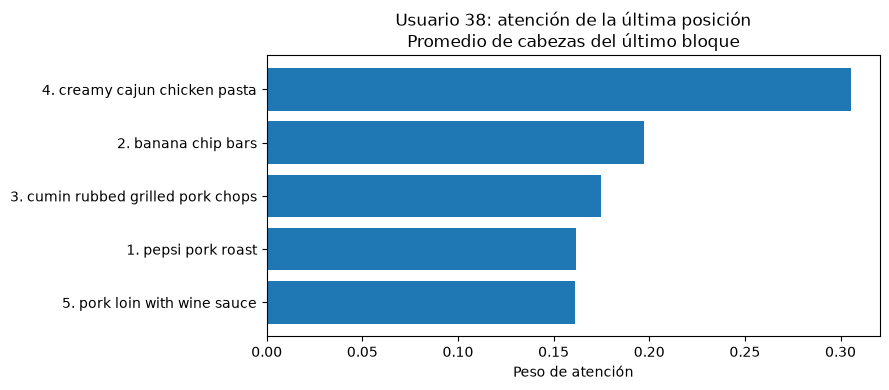


USUARIO INTERNO 9
Historial de entrada: 9 recetas; visibles para SASRec: 9
Objetivo: lemon chive rice


,Posicion_historial,item_idx,Atencion,Receta
0,1,6168,0.1045,yummy and super easy crock pot oatmeal
1,2,5622,0.1469,fruit crisp topping mix
2,3,652,0.1017,rhubarb strawberry cobbler
3,4,7071,0.1361,mom s best tomato soup canning recipe
4,5,151,0.1054,baked acorn squash with spicy maple syrup
5,6,9874,0.1072,barbecued pork chinese style
6,7,6332,0.1307,almond chocolate biscotti
7,8,4008,0.0811,better than pumpkin pie
8,9,20499,0.0864,nectarine jam


,Ranking,item_idx,Receta,Es_objetivo
0,1,4110,to die for crock pot roast,False
1,2,3839,banana banana bread,False
2,3,3812,pumpkin pie dip,False
3,4,9011,baked balsamic chicken,False
4,5,1025,delicious chicken pot pie,False
5,6,4569,reeses squares 5 ingredients no bake reese s,False
6,7,6248,creamy cajun chicken pasta,False
7,8,12359,funky chicken with sesame noodles,False
8,9,11297,kittencal s italian melt in your mouth meatballs,False
9,10,5365,creamy burrito casserole,False


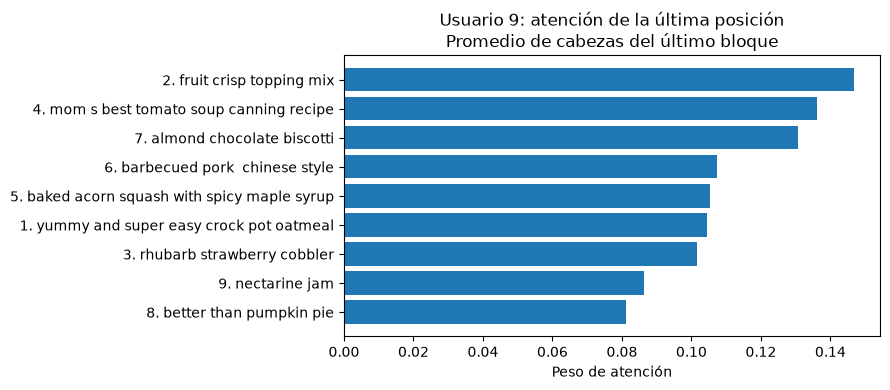


USUARIO INTERNO 139
Historial de entrada: 55 recetas; visibles para SASRec: 50
Objetivo: caramel pecan sticky bun cookies


,Posicion_historial,item_idx,Atencion,Receta
0,6,402,0.0186,flank steak with lime chipotle sauce
1,7,2083,0.0139,orange chicken crock pot
2,8,172,0.0128,coca cola brownies
3,9,1442,0.0235,rocky road fudge bars
4,10,2892,0.0290,amish country strawberry pie
5,11,3167,0.0169,copycat kfc coleslaw without the fat
6,12,3608,0.0160,roasted chicken with 20 cloves of garlic
7,13,868,0.0135,peachy crock pot pork chops
8,14,4759,0.0218,key lime pie
9,15,4538,0.0233,crock pot chops that will make you eat til you...


,Ranking,item_idx,Receta,Es_objetivo
0,1,3267,jo mama s world famous spaghetti,False
1,2,4110,to die for crock pot roast,False
2,3,1862,cracker barrel s hashbrowns casserole copycat,False
3,4,6248,creamy cajun chicken pasta,False
4,5,3839,banana banana bread,False
5,6,3812,pumpkin pie dip,False
6,7,4569,reeses squares 5 ingredients no bake reese s,False
7,8,1025,delicious chicken pot pie,False
8,9,5086,whatever floats your boat brownies,False
9,10,8799,yes virginia there is a great meatloaf,False


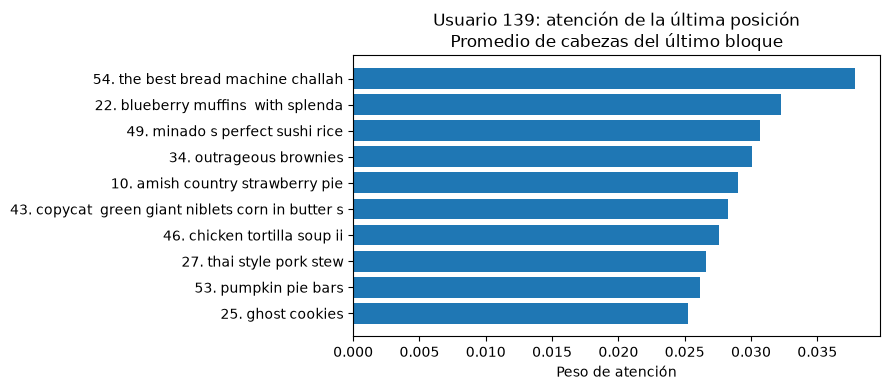

,user_idx,Longitud_train,Longitud_entrada,Objetivo,HR10
0,38,4,5,tender roast loin of pork,0.0
1,9,8,9,lemon chive rice,0.0
2,139,54,55,caramel pecan sticky bun cookies,0.0


In [25]:
# Selección reproducible según longitud, sin consultar resultados
longitudes_usuarios = pd.Series({
    u: len(train_seq[u]) for u in sorted(test_target)
})

usuarios_demo = []

for percentil in [0.25, 0.50, 0.90]:
    longitud_objetivo = longitudes_usuarios.quantile(percentil)

    candidatos = (
        longitudes_usuarios.drop(index=usuarios_demo)
        .sub(longitud_objetivo)
        .abs()
        .sort_values(kind="stable")
    )

    usuarios_demo.append(int(candidatos.index[0]))

catalogo = mapa_items.set_index("item_idx")
modelo_sasrec.eval()

resumen_casos = []

for usuario in usuarios_demo:
    historial_completo = test_hist[usuario]
    recientes = historial_completo[-MAX_LEN:]
    longitud = len(recientes)

    entrada = torch.zeros(
        (1, MAX_LEN), dtype=torch.long, device=DEVICE
    )
    entrada[0, :longitud] = torch.tensor(
        recientes, dtype=torch.long, device=DEVICE
    )

    with torch.no_grad():
        _, pesos_bloques = modelo_sasrec(
            entrada, devolver_atencion=True
        )

    # [lote, cabezas, consulta, clave]
    atencion = (
        pesos_bloques[-1][0, :, longitud - 1, :longitud]
        .mean(dim=0)
        .cpu()
        .numpy()
    )

    assert np.isfinite(atencion).all()
    assert np.isclose(atencion.sum(), 1.0, atol=1e-4)

    historial_tabla = pd.DataFrame({
        "Posicion_historial": range(
            len(historial_completo) - longitud + 1,
            len(historial_completo) + 1
        ),
        "item_idx": recientes,
        "Atencion": atencion
    })

    historial_tabla["Receta"] = historial_tabla["item_idx"].map(
        catalogo["name"]
    )

    recomendaciones = rankings_test["SASRec"][usuario][:10]

    recomendaciones_tabla = pd.DataFrame({
        "Ranking": range(1, 11),
        "item_idx": recomendaciones
    })

    recomendaciones_tabla["Receta"] = (
        recomendaciones_tabla["item_idx"].map(catalogo["name"])
    )
    recomendaciones_tabla["Es_objetivo"] = (
        recomendaciones_tabla["item_idx"].eq(test_target[usuario])
    )

    print(f"\nUSUARIO INTERNO {usuario}")
    print(
        f"Historial de entrada: {len(historial_completo)} recetas; "
        f"visibles para SASRec: {longitud}"
    )
    print("Objetivo:", catalogo.loc[test_target[usuario], "name"])

    display(historial_tabla.round(4))
    display(recomendaciones_tabla)

    # Mostrar las 10 posiciones con mayor atención
    principales = historial_tabla.nlargest(
        min(10, longitud), "Atencion"
    ).sort_values("Atencion")

    etiquetas = [
        f"{int(fila.Posicion_historial)}. {str(fila.Receta)[:45]}"
        for fila in principales.itertuples(index=False)
    ]

    fig, ax = plt.subplots(figsize=(9, 4))
    ax.barh(etiquetas, principales["Atencion"])
    ax.set_xlabel("Peso de atención")
    ax.set_title(
        f"Usuario {usuario}: atención de la última posición\n"
        "Promedio de cabezas del último bloque"
    )

    plt.tight_layout()
    fig.savefig(
        RESULTADOS / f"atencion_usuario_{usuario}.png",
        dpi=160, bbox_inches="tight"
    )
    plt.show()

    historial_tabla.to_csv(
        RESULTADOS / f"historial_atencion_usuario_{usuario}.csv",
        index=False
    )
    recomendaciones_tabla.to_csv(
        RESULTADOS / f"recomendaciones_usuario_{usuario}.csv",
        index=False
    )

    resumen_casos.append({
        "user_idx": usuario,
        "Longitud_train": len(train_seq[usuario]),
        "Longitud_entrada": len(historial_completo),
        "Objetivo": catalogo.loc[test_target[usuario], "name"],
        "HR10": metricas_usuario(
            recomendaciones, test_target[usuario], 10
        )["HR"]
    })

display(pd.DataFrame(resumen_casos))

pd.DataFrame(resumen_casos).to_csv(
    RESULTADOS / "resumen_tres_usuarios.csv",
    index=False
)

## 13. Embeddings de recetas por categoría

Proyectamos los embeddings aprendidos mediante PCA a dos dimensiones.
Coloreamos las recetas según una selección fija de etiquetas de Food.com.

Una receta puede tener varias etiquetas; asignamos la primera que
coincida según el orden declarado. Esta categoría se utiliza solo
para visualizar y no modifica el modelo.

La proyección es exploratoria: dos dimensiones no conservan toda
la información y una separación visual no demuestra calidad predictiva.

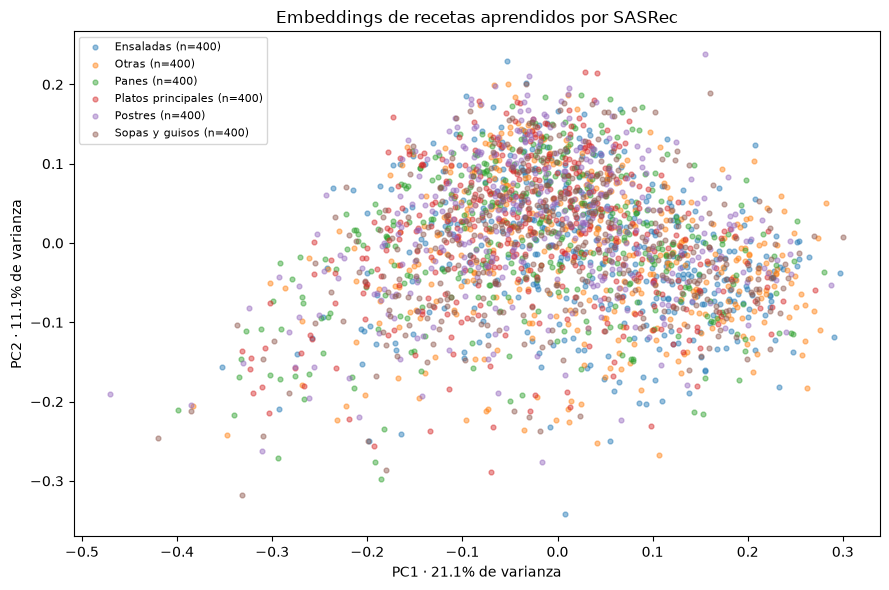

Recetas visualizadas: 2,400
Varianza explicada por ambas componentes: 32.15%


,Recetas
Categoria,
Panes,400
Platos principales,400
Postres,400
Otras,400
Sopas y guisos,400
Ensaladas,400


In [26]:
from sklearn.decomposition import PCA

# Orden fijo para resolver recetas con varias etiquetas
CATEGORIAS_VISUAL = [
    ("desserts", "Postres"),
    ("breads", "Panes"),
    ("soups-stews", "Sopas y guisos"),
    ("salads", "Ensaladas"),
    ("main-dish", "Platos principales"),
]

def categoria_visual(texto_tags):
    etiquetas = set(ast.literal_eval(texto_tags))

    for etiqueta, nombre in CATEGORIAS_VISUAL:
        if etiqueta in etiquetas:
            return nombre

    return "Otras"

catalogo_visual = mapa_items.copy()
catalogo_visual["Categoria"] = catalogo_visual["tags"].apply(
    categoria_visual
)

# Excluir la receta sin evidencia de entrenamiento
catalogo_visual = catalogo_visual[
    catalogo_visual["item_idx"].isin(items_train)
].copy()

# Muestra reproducible de hasta 400 recetas por categoría
muestras = []

for categoria, grupo in catalogo_visual.groupby("Categoria"):
    muestras.append(
        grupo.sample(n=min(400, len(grupo)), random_state=SEED)
    )

muestra_embeddings = pd.concat(
    muestras, ignore_index=True
).sort_values("item_idx").reset_index(drop=True)

indices = muestra_embeddings["item_idx"].to_numpy()

embeddings = (
    modelo_sasrec.item_embedding.weight
    .detach()
    .cpu()
    .numpy()[indices]
)

pca = PCA(n_components=2, svd_solver="full")
coordenadas = pca.fit_transform(embeddings)

muestra_embeddings["PC1"] = coordenadas[:, 0]
muestra_embeddings["PC2"] = coordenadas[:, 1]

fig, ax = plt.subplots(figsize=(9, 6))

for categoria, grupo in muestra_embeddings.groupby("Categoria"):
    ax.scatter(
        grupo["PC1"],
        grupo["PC2"],
        s=12,
        alpha=0.45,
        label=f"{categoria} (n={len(grupo)})"
    )

varianza = pca.explained_variance_ratio_

ax.set_xlabel(f"PC1 · {100 * varianza[0]:.1f}% de varianza")
ax.set_ylabel(f"PC2 · {100 * varianza[1]:.1f}% de varianza")
ax.set_title("Embeddings de recetas aprendidos por SASRec")
ax.legend(fontsize=8)

plt.tight_layout()
fig.savefig(
    RESULTADOS / "embeddings_por_categoria.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

print(f"Recetas visualizadas: {len(muestra_embeddings):,}")
print(
    "Varianza explicada por ambas componentes: "
    f"{100 * varianza.sum():.2f}%"
)

display(
    muestra_embeddings["Categoria"]
    .value_counts()
    .rename_axis("Categoria")
    .to_frame("Recetas")
)

muestra_embeddings[
    ["item_idx", "name", "Categoria", "PC1", "PC2"]
].to_csv(
    RESULTADOS / "embeddings_pca.csv",
    index=False
)

## 14. Costo computacional

Reportamos tiempos medidos en el mismo equipo. Popularidad,
reglas e ítem–ítem usan CPU; SASRec utiliza MPS.

La inferencia corresponde al tiempo total de generación de rankings
dividido por usuarios. Es un promedio de procesamiento y no equivale
a la latencia de una solicitud individual en el dashboard.

Para SASRec separamos entrenamiento y validación. El costo de búsqueda
incluye las tres configuraciones, mientras que el modelo final conserva
solo el checkpoint seleccionado.

Las líneas base no tienen parámetros entrenados por gradiente,
pero sí almacenan estadísticas, reglas o matrices.

In [27]:
# Registrar la popularidad para cargarla después en el dashboard
tabla_pop.to_csv(
    CARPETA_MODELOS / "popularidad.csv", index=False
)

curvas_costos = pd.DataFrame(curvas_sasrec)
curva_ganadora = curvas_costos[
    curvas_costos["Modelo"] == nombre_ganador
]

parametros_ganador = int(
    seleccion_sasrec.loc[
        seleccion_sasrec["Modelo"] == nombre_ganador,
        "Parametros"
    ].iloc[0]
)

def peso_archivo_mb(nombre):
    return (CARPETA_MODELOS / nombre).stat().st_size / 1_000_000

tabla_costos = pd.DataFrame([
    {
        "Modelo": "Popularidad",
        "Dispositivo": "CPU",
        "Ajuste_train_s": tiempo_ajuste_pop,
        "Validacion_s": np.nan,
        "Inferencia_promedio_ms_usuario":
            1000 * tiempo_inferencia_pop / N_USUARIOS,
        "Parametros_gradiente": 0,
        "Archivo_MB": peso_archivo_mb("popularidad.csv"),
    },
    {
        "Modelo": "Item-Item",
        "Dispositivo": "CPU",
        "Ajuste_train_s": tiempo_ajuste_i2i,
        "Validacion_s": np.nan,
        "Inferencia_promedio_ms_usuario":
            1000 * tiempo_inferencia_i2i / N_USUARIOS,
        "Parametros_gradiente": 0,
        "Archivo_MB": peso_archivo_mb("items_normalizados.npz"),
    },
    {
        "Modelo": "Reglas + popularidad",
        "Dispositivo": "CPU",
        "Ajuste_train_s": tiempo_ajuste_reglas,
        "Validacion_s": np.nan,
        "Inferencia_promedio_ms_usuario":
            1000 * tiempo_inferencia_reglas / N_USUARIOS,
        "Parametros_gradiente": 0,
        "Archivo_MB":
            peso_archivo_mb("reglas_asociacion.csv")
            + peso_archivo_mb("popularidad.csv"),
    },
    {
        "Modelo": "SASRec",
        "Dispositivo": str(DEVICE),
        # Incluye las épocas ejecutadas hasta parada temprana
        "Ajuste_train_s": curva_ganadora["Segundos_train"].sum(),
        "Validacion_s": curva_ganadora["Segundos_val"].sum(),
        "Inferencia_promedio_ms_usuario":
            1000 * tiempo_inferencia_sasrec / N_USUARIOS,
        "Parametros_gradiente": parametros_ganador,
        "Archivo_MB": peso_archivo_mb("sasrec.pt"),
    },
])

display(tabla_costos.round(4))

tabla_costos.to_csv(
    RESULTADOS / "costos_modelos.csv", index=False
)

print(
    "Búsqueda SASRec: entrenamiento de las 3 configuraciones = "
    f"{curvas_costos['Segundos_train'].sum():.2f} s"
)
print(
    "Búsqueda SASRec: validación de las 3 configuraciones = "
    f"{curvas_costos['Segundos_val'].sum():.2f} s"
)
print(
    "Tiempo total registrado de la búsqueda = "
    f"{seleccion_sasrec['Segundos_total'].sum():.2f} s"
)

# Tabla conjunta de resultados y costos
tabla_final = comparacion_test.merge(
    tabla_costos, on="Modelo", validate="many_to_one"
)

tabla_final.to_csv(
    RESULTADOS / "comparacion_final_con_costos.csv",
    index=False
)

# Comprobar archivos obligatorios
obligatorios = [
    PROYECTO / "Notebooks" / "01_entrega1.ipynb",
    SALIDA_DATOS / "secuencias.parquet",
    SALIDA_DATOS / "mapa_items.csv",
    SALIDA_DATOS / "metricas.csv",
    CARPETA_MODELOS / "sasrec.pt",
]

display(pd.DataFrame([
    {
        "Archivo": str(ruta.relative_to(PROYECTO)),
        "Existe": ruta.is_file(),
        "MB": (
            ruta.stat().st_size / 1_000_000
            if ruta.is_file() else np.nan
        )
    }
    for ruta in obligatorios
]).round(3))

,Modelo,Dispositivo,Ajuste_train_s,Validacion_s,Inferencia_promedio_ms_usuario,Parametros_gradiente,Archivo_MB
0,Popularidad,CPU,0.0224,NaN,0.0015,0,0.3335
1,Item-Item,CPU,0.0043,NaN,1.6746,0,1.1919
2,Reglas + popularidad,CPU,0.1814,NaN,0.0033,0,0.3372
3,SASRec,mps,13.0691,234.5875,2.1613,2692736,10.7759


Búsqueda SASRec: entrenamiento de las 3 configuraciones = 52.11 s
Búsqueda SASRec: validación de las 3 configuraciones = 711.20 s
Tiempo total registrado de la búsqueda = 763.42 s


,Archivo,Existe,MB
0,Notebooks/01_entrega1.ipynb,True,0.195
1,data/secuencias.parquet,True,2.670
2,data/mapa_items.csv,True,19.036
3,data/metricas.csv,True,0.001
4,modelos/sasrec.pt,True,10.776


## 15. Conclusiones y limitaciones

### ¿Vale la pena el Transformer en este rubro?

En este experimento, SASRec no demuestra una superioridad general
frente a popularidad. En prueba obtiene NDCG@10 de 0,011639,
frente a 0,011602 de popularidad: una diferencia absoluta muy pequeña.
En HR@20, popularidad obtiene 4,12 % y SASRec 3,84 %.

SASRec amplía la cobertura@20 desde 0,21 % hasta 2,10 %.
Para usuarios con historiales largos, su HR@10 es ligeramente mayor
que el de popularidad: 2,29 % frente a 2,17 %. Estas diferencias
por segmento son descriptivas y no demuestran superioridad estadística.

Ítem–ítem alcanza la mayor cobertura@20, 74,50 %, pero presenta
menor acierto global. Las reglas aportan pocas recomendaciones:
en validación, solo 1,56 posiciones del top-20 provienen de reglas
en promedio; el resto se completa con popularidad.

Los análisis de ingredientes y de historiales desordenados no
aportan evidencia concluyente de una ventaja del orden cronológico.
Por tanto, implementamos un modelo que utiliza el orden, pero no
demostramos que ese orden produzca una mejora consistente.

Considerando precisión y costo, popularidad es una referencia
competitiva para este experimento. SASRec permite explorar
personalización y mayor cobertura, pero los resultados actuales
no justifican afirmar que reemplaza ventajosamente a las líneas base.

### Limitaciones

- Las interacciones son reseñas, no evidencia directa de preparación,
  consumo o satisfacción.
- Conservamos todas las valoraciones como interacciones, incluidas
  las negativas y las de valor cero.
- Las fechas tienen precisión diaria; el orden dentro del día
  se resuelve mediante un desempate reproducible.
- El filtro 5-core favorece usuarios y recetas con actividad suficiente.
- Leave-last-out ordena el historial de cada usuario, pero no impone
  un corte temporal global: no simula estrictamente un despliegue
  donde toda la información futura sea desconocida.
- SASRec considera como máximo 50 recetas por entrada y su atención
  no cruza entre bloques de entrenamiento.
- Los negativos muestreados son interacciones no observadas,
  no rechazos explícitos.
- Se probaron tres configuraciones con una sola semilla.
  Fijar semillas no garantiza resultados idénticos entre dispositivos
  y versiones.
- La atención no constituye una explicación causal.
- La proyección PCA muestra solo el 32,15 % de la varianza de la muestra.